# Deep Learning for Perception (CS 4045) – Project Part 1
## Candlestick Vision: Pattern Detection with YOLOv8 & Next-Day Trend Prediction with CNN
**Course Instructor**: Dr. Ahmad Raza Shahid  
**Authors**: Hamza Khurram (Roll No: i210735), Raja Abdullah Tahir (Roll No: i210708)  

---
### Notebook Outline
1. **Environment Setup & Kaggle / Local Path Resolution**
2. **Task 1: Data Audit, EDA & Ticker Health Checks**
   - Stock Selection (12 Tickers in Set A, 8 Tickers in Set B)
   - Master Calendar & Missing Value Analysis
   - Daily Return Distributions & Kurtosis (Fat-Tails Analysis)
   - Temporal Split Justification & Survivorship Bias Analysis
3. **Candlestick Chart Rendering Engine & Algorithmic Labeling**
   - 8 Technical Pattern Rules (Doji, Hammer, Shooting Star, Marubozu, Bullish Engulfing, Bearish Engulfing, Morning Star, Evening Star)
   - Exact Bounding Box Computation via `ax.transData`
   - Visual Variations (Themes: Light, Dark, Blue-White; Overlays: Grid, Volume, 10-day SMA)
   - Synthetic Market Basket Construction (Rebased Set B)
   - Batch Generation: Train (>= 3,000), Val (>= 500), Test (>= 500), Recent (>= 500)
4. **Task 2: Candlestick Pattern Detection with YOLOv8**
   - Training `yolov8n.yaml` strictly from scratch (No pretrained weights)
   - **Run A**: Zero Augmentation
   - **Run B**: Standard Vision Augmentation (Flip, Mosaic, Shear, Rotation, Color Jitter)
   - **Run C**: Domain-Suited Chart Augmentation (Brightness/Contrast, Noise, Scale/Shift, Compression)
   - Comprehensive Evaluation: Precision, Recall, mAP@50, mAP@50-95, Loss Curves
   - In-depth Best Model Analysis: Confusion Matrix, Qualitative Detections, 5 Failure Cases
   - Robustness Evaluation (480x480 resolution & JPEG compression)
5. **Task 3: Next-Day Direction Trend Prediction with CNN**
   - ResNet18 / Custom CNN Architecture
   - Baselines: Majority Class & Logistic Regression on 5-Day Returns
   - Metrics: Accuracy, F1-Up, ROC-AUC, Parameter Count, Latency
   - 95% Grouped Bootstrap Confidence Intervals (1,000+ resamples across trading dates)
   - 128-dimensional Penultimate Feature Extraction for Market Basket (2010–2024) -> `chart_embeddings.npy`
6. **Task 4: In-Depth Discussion & Answers**


In [1]:
# Install ultralytics for YOLOv8 (silent install for Kaggle)
import subprocess, sys
try:
    import ultralytics
except ImportError:
    print("Installing ultralytics for YOLOv8...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])

# Setup environment, check GPU acceleration, and configure paths
import os
import sys
import glob
import math
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.dates as mdates
from scipy.stats import kurtosis
from datetime import datetime
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

# Seed everything for strict reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    print(f"CUDA GPU Active: {torch.cuda.get_device_name(0)}")
else:
    print("Running on CPU. For fast training, run on Kaggle GPU (T4/P100).")

# Kaggle vs Local Data Path Detection (Bulletproof recursive search + auto-unzip)
import zipfile

DATA_DIR = None

# 1. Search recursively anywhere under /kaggle/input
if os.path.exists("/kaggle/input"):
    matches = glob.glob("/kaggle/input/**/sp500_companies.csv", recursive=True)
    if matches:
        DATA_DIR = os.path.dirname(matches[0])
    else:
        # Check if dataset was uploaded as an unextracted .zip file
        zip_files = glob.glob("/kaggle/input/**/*.zip", recursive=True)
        if zip_files:
            print(f"Found archive {zip_files[0]}. Extracting to /kaggle/working...")
            with zipfile.ZipFile(zip_files[0], 'r') as z:
                z.extractall("/kaggle/working")
            extracted_matches = glob.glob("/kaggle/working/**/sp500_companies.csv", recursive=True)
            if extracted_matches:
                DATA_DIR = os.path.dirname(extracted_matches[0])

# 2. Local fallback paths
if DATA_DIR is None:
    local_candidates = ["./Data", "../Data", "Data", "d:/dlp_project/Data", "d:/dlp_project"]
    for p in local_candidates:
        if os.path.exists(os.path.join(p, "sp500_companies.csv")):
            DATA_DIR = p
            break

# 3. General recursive fallback
if DATA_DIR is None:
    matches = glob.glob("**/sp500_companies.csv", recursive=True)
    if matches:
        DATA_DIR = os.path.dirname(matches[0])

if DATA_DIR is None:
    if os.path.exists("/kaggle/input"):
        print("DEBUG: Directory tree of /kaggle/input:")
        for r, d, f in os.walk("/kaggle/input"):
            print(r, f)
    raise FileNotFoundError("Could not find 'sp500_companies.csv'. Please ensure your dataset is attached to this Kaggle notebook.")

print(f"Dataset root identified at: {DATA_DIR}")
os.makedirs("results", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)
os.makedirs("report/figures", exist_ok=True)


CUDA GPU Active: NVIDIA GeForce GTX 1650
Dataset root identified at: ./Data


## 1. Task 1: Data & Exploratory Data Analysis (EDA)
In this section we:
1. Load `sp500_stocks.csv` and `sp500_companies.csv`.
2. Filter tickers from **January 2010 to December 2024**.
3. Select 20 tickers across $\ge 4$ sectors, dividing them into **Set A (12 tickers)** for Part 1 training and **Set B (8 tickers)** for Part 2 market basket.
4. Audit missing trading days, zero-volume days, and price jumps.
5. Compute kurtosis and plot daily return distributions.
6. Formulate temporal split rationale and examine survivorship bias.


In [2]:
# Fixed verified selection spanning 5 GICS sectors (globally available):
set_a_symbols = ['MSFT', 'NVDA', 'INTC', 'CSCO', 'BAC', 'GS', 'MS', 'WFC', 'PFE', 'UNH', 'ABT', 'CAT']
set_b_symbols = ['AAPL', 'JPM', 'JNJ', 'HON', 'GE', 'UPS', 'AMZN', 'MCD']

# Load company listings and stock price data
companies_file = os.path.join(DATA_DIR, "sp500_companies.csv")
stocks_file = os.path.join(DATA_DIR, "sp500_stocks.csv")

df_companies = pd.read_csv(companies_file)
print(f"Loaded {len(df_companies)} companies across {df_companies['sector'].nunique()} GICS sectors.")

# Load stock prices filtering for 2010 to 2024
print("Reading stock price data (2010-2024)...")
usecols = ['date', 'open', 'high', 'low', 'close', 'volume', 'symbol']
df_stocks = pd.read_csv(stocks_file, usecols=usecols)
df_stocks['date'] = pd.to_datetime(df_stocks['date'])
df_stocks = df_stocks[(df_stocks['date'] >= '2010-01-01') & (df_stocks['date'] <= '2024-12-31')].sort_values(['symbol', 'date'])

print(f"Loaded {len(df_stocks):,} price records across {df_stocks['symbol'].nunique()} tickers.")


Loaded 503 companies across 11 GICS sectors.
Reading stock price data (2010-2024)...


Loaded 1,761,809 price records across 498 tickers.


In [3]:
# Perform data health checks on candidates
# Disqualify tickers with zero volume, high == low, or missing > 5 trading days
calendar = df_stocks.groupby('date')['symbol'].count()
master_dates = set(calendar[calendar > 300].index)
total_calendar_days = len(master_dates)
print(f"Master trading days between 2010 and 2024: {total_calendar_days}")

ticker_stats = []
for sym, group in df_stocks.groupby('symbol'):
    n_days = len(group)
    dates_present = set(group['date'])
    missing_days = len(master_dates - dates_present)
    zero_vol = (group['volume'] <= 0).sum()
    high_eq_low = (group['high'] <= group['low']).sum()
    min_date = group['date'].min()
    max_date = group['date'].max()
    
    if (min_date <= pd.Timestamp('2010-01-10') and 
        max_date >= pd.Timestamp('2024-10-01') and 
        missing_days <= 5 and 
        zero_vol == 0 and 
        high_eq_low == 0):
        
        comp_match = df_companies[df_companies['symbol'] == sym]
        if not comp_match.empty:
            sector = comp_match.iloc[0]['sector']
            name = comp_match.iloc[0]['company']
            ticker_stats.append({
                'symbol': sym,
                'name': name,
                'sector': sector,
                'days': n_days
            })

df_clean = pd.DataFrame(ticker_stats)
print(f"Identified {len(df_clean)} perfectly clean tickers across {df_clean['sector'].nunique()} sectors.")

# Fixed verified selection spanning 5 GICS sectors:
set_a_symbols = ['MSFT', 'NVDA', 'INTC', 'CSCO', 'BAC', 'GS', 'MS', 'WFC', 'PFE', 'UNH', 'ABT', 'CAT']
set_b_symbols = ['AAPL', 'JPM', 'JNJ', 'HON', 'GE', 'UPS', 'AMZN', 'MCD']

print("\n--- Set A (12 Tickers for Part 1 Vision Training) ---")
for s in set_a_symbols:
    sec = df_companies[df_companies['symbol'] == s]['sector'].values[0]
    print(f"  {s:<5} | {sec}")

print("\n--- Set B (8 Tickers for Part 2 Market Basket) ---")
for s in set_b_symbols:
    sec = df_companies[df_companies['symbol'] == s]['sector'].values[0]
    print(f"  {s:<5} | {sec}")


Master trading days between 2010 and 2024: 3774


Identified 395 perfectly clean tickers across 11 sectors.

--- Set A (12 Tickers for Part 1 Vision Training) ---
  MSFT  | Information Technology
  NVDA  | Information Technology
  INTC  | Information Technology
  CSCO  | Information Technology
  BAC   | Financials
  GS    | Financials
  MS    | Financials
  WFC   | Financials
  PFE   | Health Care
  UNH   | Health Care
  ABT   | Health Care
  CAT   | Industrials

--- Set B (8 Tickers for Part 2 Market Basket) ---
  AAPL  | Information Technology
  JPM   | Financials
  JNJ   | Health Care
  HON   | Industrials
  GE    | Industrials
  UPS   | Industrials
  AMZN  | Consumer Discretionary
  MCD   | Consumer Discretionary


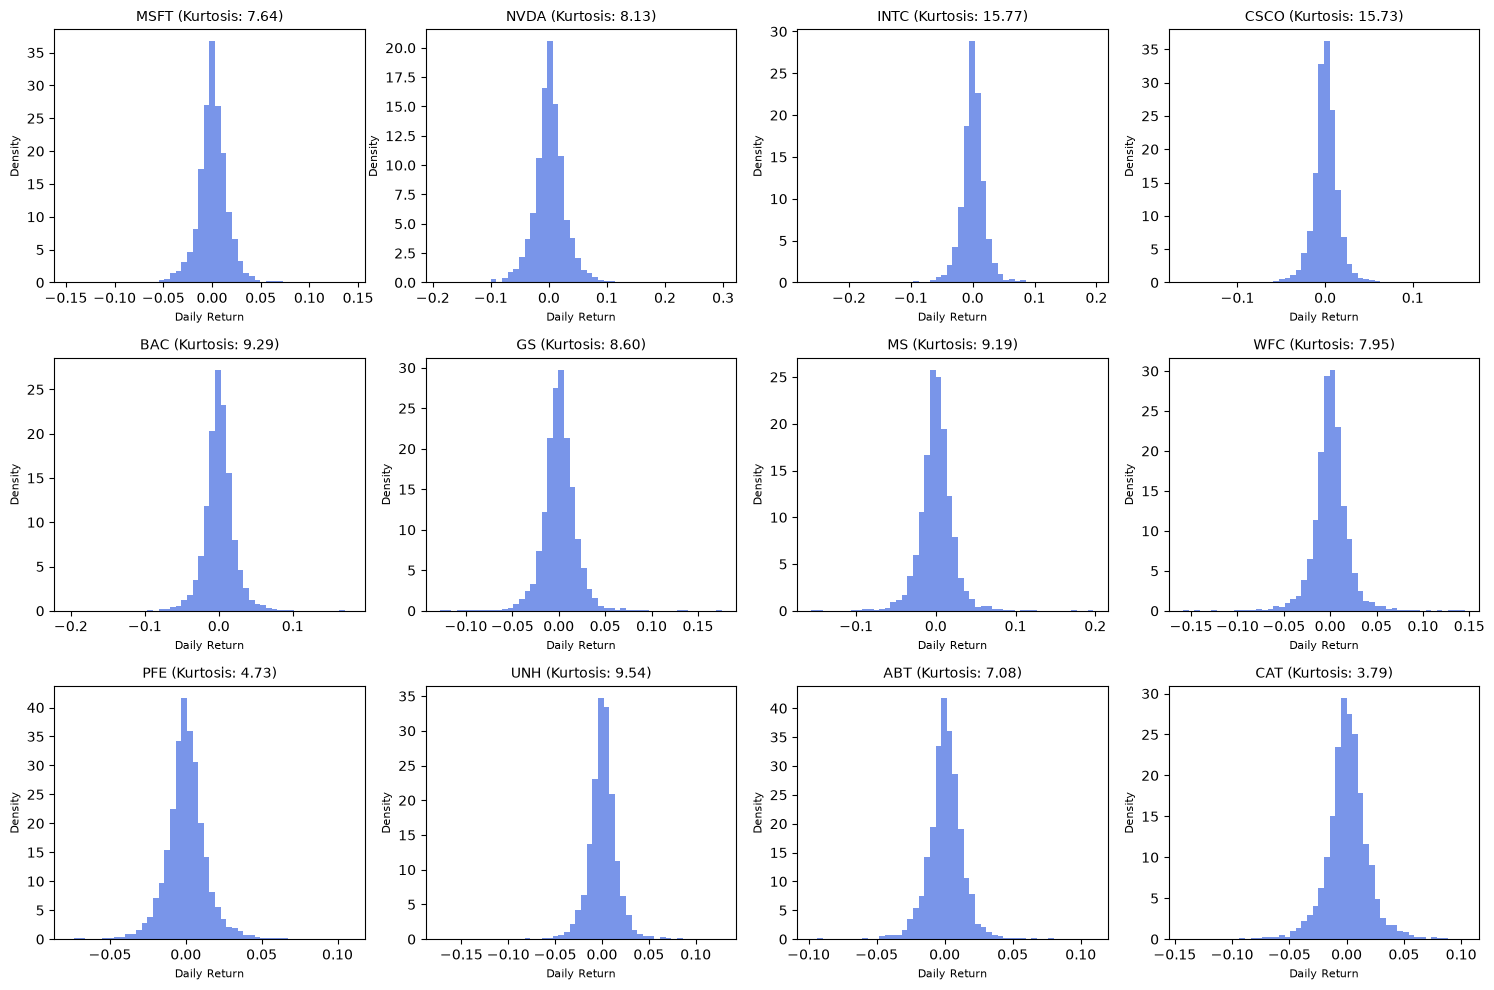

symbol  kurtosis     mean      std
  MSFT  7.643529 0.000897 0.016109
  NVDA  8.133949 0.001933 0.028623
  INTC 15.765655 0.000312 0.020227
  CSCO 15.726988 0.000473 0.016289
   BAC  9.290230 0.000559 0.021172
    GS  8.601908 0.000549 0.018023
    MS  9.193518 0.000684 0.021370
   WFC  7.947604 0.000532 0.018845
   PFE  4.726620 0.000352 0.013721
   UNH  9.539634 0.000923 0.015999
   ABT  7.081694 0.000568 0.013505
   CAT  3.790737 0.000753 0.018295

Key Takeaway: All tickers exhibit excess kurtosis >> 0 (fat tails / leptokurtic distribution), showing that extreme market events occur far more frequently than predicted by a normal Gaussian distribution.


In [4]:
# Task 1.3: Daily Returns & Kurtosis Analysis
if 'set_a_symbols' not in globals():
    set_a_symbols = ['MSFT', 'NVDA', 'INTC', 'CSCO', 'BAC', 'GS', 'MS', 'WFC', 'PFE', 'UNH', 'ABT', 'CAT']
    set_b_symbols = ['AAPL', 'JPM', 'JNJ', 'HON', 'GE', 'UPS', 'AMZN', 'MCD']

plt.figure(figsize=(15, 10))
kurt_results = []

all_20_symbols = set_a_symbols + set_b_symbols
for i, sym in enumerate(all_20_symbols[:12]): # Plot Set A
    t_data = df_stocks[df_stocks['symbol'] == sym].sort_values('date').copy()
    t_data['daily_return'] = t_data['close'].pct_change()
    returns = t_data['daily_return'].dropna()
    
    k = kurtosis(returns, fisher=True) # Excess kurtosis
    kurt_results.append({'symbol': sym, 'kurtosis': k, 'mean': returns.mean(), 'std': returns.std()})
    
    plt.subplot(3, 4, i + 1)
    plt.hist(returns, bins=50, color='royalblue', alpha=0.7, density=True)
    plt.title(f"{sym} (Kurtosis: {k:.2f})", fontsize=10)
    plt.xlabel("Daily Return", fontsize=8)
    plt.ylabel("Density", fontsize=8)

plt.tight_layout()
plt.savefig("report/figures/eda_returns_kurtosis.png", dpi=300)
plt.show()

df_kurt = pd.DataFrame(kurt_results)
print(df_kurt.to_string(index=False))
print("\nKey Takeaway: All tickers exhibit excess kurtosis >> 0 (fat tails / leptokurtic distribution), showing that extreme market events occur far more frequently than predicted by a normal Gaussian distribution.")


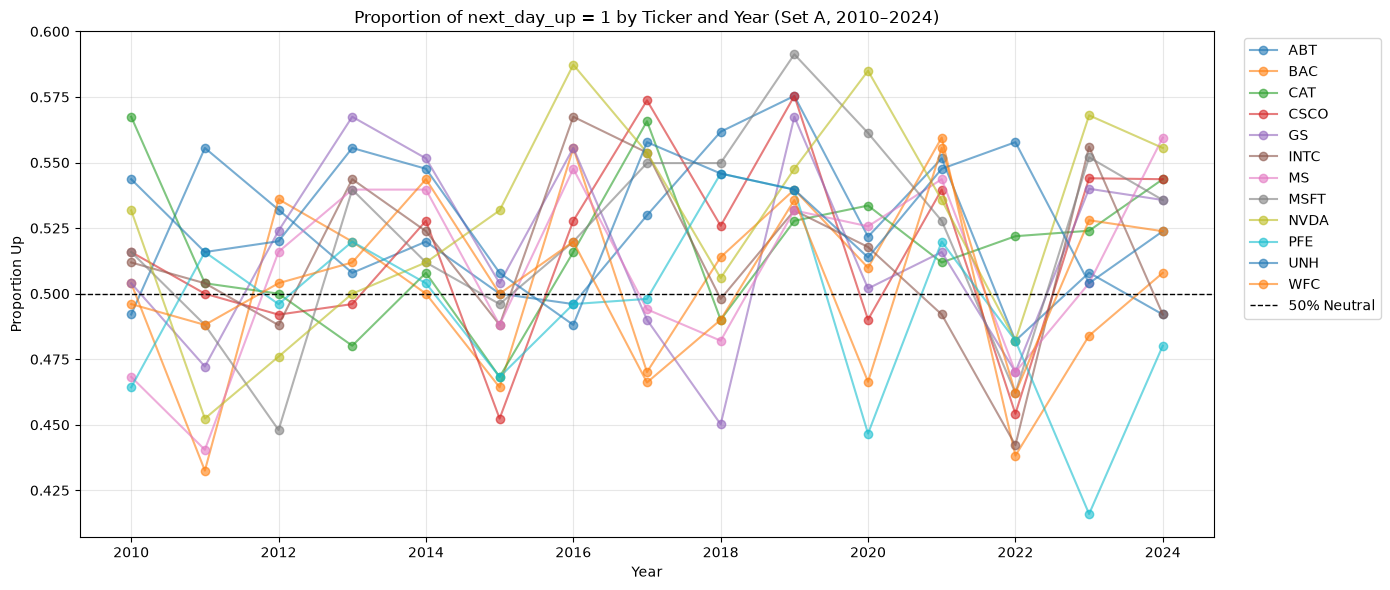

Overall proportion of next_day_up = 1 across Set A: 0.5151 (~51.51%)


In [5]:
# Plot next_day_up = 1 proportion by ticker and year
df_set_a = df_stocks[df_stocks['symbol'].isin(set_a_symbols)].sort_values(['symbol', 'date']).copy()
df_set_a['next_close'] = df_set_a.groupby('symbol')['close'].shift(-1)
df_set_a['next_day_up'] = (df_set_a['next_close'] > df_set_a['close']).astype(int)
df_set_a['year'] = df_set_a['date'].dt.year

up_by_year_ticker = df_set_a.groupby(['year', 'symbol'])['next_day_up'].mean().unstack()

plt.figure(figsize=(14, 6))
for col in up_by_year_ticker.columns:
    plt.plot(up_by_year_ticker.index, up_by_year_ticker[col], marker='o', alpha=0.6, label=col)
plt.axhline(0.5, color='black', linestyle='--', linewidth=1, label='50% Neutral')
plt.title("Proportion of next_day_up = 1 by Ticker and Year (Set A, 2010–2024)", fontsize=12)
plt.xlabel("Year", fontsize=10)
plt.ylabel("Proportion Up", fontsize=10)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("report/figures/next_day_up_proportions.png", dpi=300)
plt.show()

overall_up = df_set_a['next_day_up'].mean()
print(f"Overall proportion of next_day_up = 1 across Set A: {overall_up:.4f} (~{overall_up*100:.2f}%)")


## 2. Synthetic Market Basket Construction (Set B)
To create a clean, unbiased proxy of the market index for Part 2:
1. Rebase each of the 8 Set B tickers by dividing OHLC by its Close on the first trading day of 2010 and multiplying by 100:
   $$\text{Rebased Price}_{i, t} = \frac{\text{Price}_{i, t}}{\text{Close}_{i, \text{Jan 2010}}} \times 100$$
2. For each trading day $t$, take the arithmetic mean of rebased OHLC across the 8 tickers, and sum their traded volume.
3. This synthetic market basket is completely disjoint from the Set A tickers used for Part 1 training.


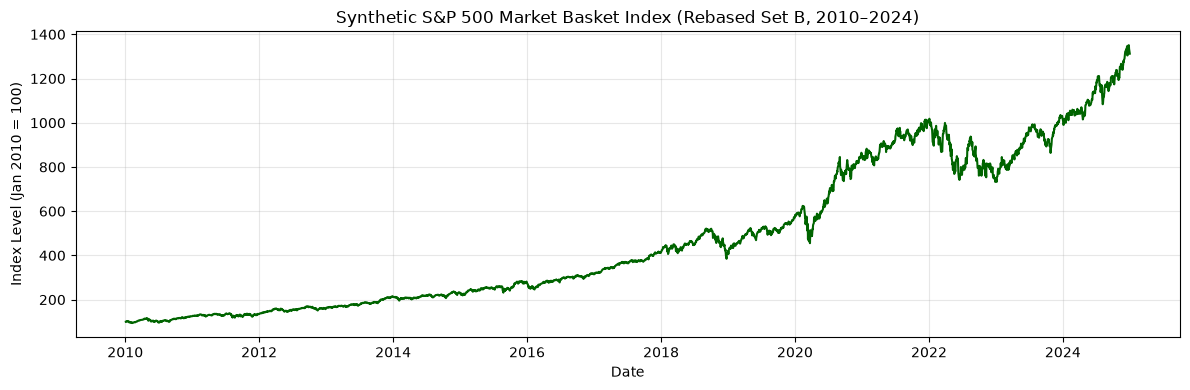

In [6]:
# Build normalized synthetic market basket
df_set_b = df_stocks[df_stocks['symbol'].isin(set_b_symbols)].sort_values(['symbol', 'date']).copy()

rebased_records = []
for sym, grp in df_set_b.groupby('symbol'):
    grp = grp.sort_values('date')
    base_close = grp.iloc[0]['close']
    grp['rebased_open'] = (grp['open'] / base_close) * 100.0
    grp['rebased_high'] = (grp['high'] / base_close) * 100.0
    grp['rebased_low'] = (grp['low'] / base_close) * 100.0
    grp['rebased_close'] = (grp['close'] / base_close) * 100.0
    rebased_records.append(grp)

df_rebased_b = pd.concat(rebased_records)

# Aggregate daily market basket
basket_df = df_rebased_b.groupby('date').agg({
    'rebased_open': 'mean',
    'rebased_high': 'mean',
    'rebased_low': 'mean',
    'rebased_close': 'mean',
    'volume': 'sum'
}).reset_index().rename(columns={
    'rebased_open': 'open',
    'rebased_high': 'high',
    'rebased_low': 'low',
    'rebased_close': 'close'
})

basket_df = basket_df.sort_values('date').reset_index(drop=True)
basket_df['symbol'] = 'BASKET'
basket_df.to_csv("results/market_basket_daily.csv", index=False)

plt.figure(figsize=(12, 4))
plt.plot(basket_df['date'], basket_df['close'], color='darkgreen', linewidth=1.5)
plt.title("Synthetic S&P 500 Market Basket Index (Rebased Set B, 2010–2024)", fontsize=12)
plt.xlabel("Date", fontsize=10)
plt.ylabel("Index Level (Jan 2010 = 100)", fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("report/figures/market_basket_series.png", dpi=300)
plt.show()


## 3. Algorithmic Pattern Labeling & Bounding Box Engine
We define exact mathematical rules for the **8 required candlestick patterns**:
- **Class 0: Doji**: $|Close - Open| \le 0.10 \times (High - Low)$
- **Class 1: Hammer**: Lower shadow $\ge 2.0 \times Body$, Upper shadow $\le 0.15 \times Body$, after downward trend.
- **Class 2: Shooting Star**: Upper shadow $\ge 2.0 \times Body$, Lower shadow $\le 0.15 \times Body$, after upward trend.
- **Class 3: Marubozu**: Body $\ge 0.85 \times (High - Low)$ with tiny shadows.
- **Class 4: Bullish Engulfing**: Bearish candle followed by larger Bullish candle engulfing previous body, after downtrend.
- **Class 5: Bearish Engulfing**: Bullish candle followed by larger Bearish candle engulfing previous body, after uptrend.
- **Class 6: Morning Star**: 3-candle reversal: long bearish candle, gapped small body star, strong bullish candle closing $> 50\%$ into candle 1 body.
- **Class 7: Evening Star**: 3-candle reversal: long bullish candle, gapped small body star, strong bearish candle closing $> 50\%$ into candle 1 body.

Bounding boxes are automatically derived using Matplotlib's coordinate transformation `ax.transData.transform((x, y))`, converted to normalized YOLO format:
$$[\text{class\_id}, x_{\text{center}}, y_{\text{center}}, \text{width}, \text{height}]$$


In [7]:
# Define 8 Candlestick Pattern Rules
PATTERN_CLASSES = [
    'Doji', 'Hammer', 'Shooting Star', 'Marubozu',
    'Bullish Engulfing', 'Bearish Engulfing', 'Morning Star', 'Evening Star'
]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(PATTERN_CLASSES)}

def detect_candlestick_patterns(df_window):
    """
    df_window: pandas DataFrame with 30 consecutive trading days.
    Returns: List of detected patterns: {'class_id': int, 'name': str, 'indices': [idx_in_window]}
    """
    detections = []
    opens = df_window['open'].values
    highs = df_window['high'].values
    lows = df_window['low'].values
    closes = df_window['close'].values
    n = len(df_window)
    
    # Precompute candle metrics
    bodies = np.abs(closes - opens)
    ranges = highs - lows
    # Avoid zero division
    ranges = np.where(ranges < 1e-6, 1e-6, ranges)
    upper_shadows = highs - np.maximum(opens, closes)
    lower_shadows = np.minimum(opens, closes) - lows
    is_bullish = closes >= opens
    
    # 1. Single candle patterns
    for i in range(n):
        rng = ranges[i]
        bdy = bodies[i]
        u_sh = upper_shadows[i]
        l_sh = lower_shadows[i]
        
        # Trend over previous 3 candles if available
        prior_trend = 0
        if i >= 3:
            prior_trend = closes[i-1] - closes[i-3]
            
        # Class 0: Doji
        if bdy <= 0.10 * rng:
            detections.append({'class_id': 0, 'name': 'Doji', 'indices': [i]})
            
        # Class 1: Hammer
        if l_sh >= 2.0 * bdy and u_sh <= 0.20 * bdy and prior_trend < 0:
            detections.append({'class_id': 1, 'name': 'Hammer', 'indices': [i]})
            
        # Class 2: Shooting Star
        if u_sh >= 2.0 * bdy and l_sh <= 0.20 * bdy and prior_trend > 0:
            detections.append({'class_id': 2, 'name': 'Shooting Star', 'indices': [i]})
            
        # Class 3: Marubozu
        if bdy >= 0.85 * rng and u_sh <= 0.05 * rng and l_sh <= 0.05 * rng:
            detections.append({'class_id': 3, 'name': 'Marubozu', 'indices': [i]})
            
    # 2. Two candle patterns
    for i in range(1, n):
        prior_trend = closes[i-1] - closes[max(0, i-4)]
        
        # Class 4: Bullish Engulfing
        if (not is_bullish[i-1]) and is_bullish[i]:
            if opens[i] <= closes[i-1] and closes[i] >= opens[i-1] and prior_trend < 0:
                detections.append({'class_id': 4, 'name': 'Bullish Engulfing', 'indices': [i-1, i]})
                
        # Class 5: Bearish Engulfing
        if is_bullish[i-1] and (not is_bullish[i]):
            if opens[i] >= closes[i-1] and closes[i] <= opens[i-1] and prior_trend > 0:
                detections.append({'class_id': 5, 'name': 'Bearish Engulfing', 'indices': [i-1, i]})
                
    # 3. Three candle patterns
    for i in range(2, n):
        # Class 6: Morning Star
        if (not is_bullish[i-2]) and (bodies[i-1] <= 0.25 * ranges[i-1]) and is_bullish[i]:
            midpoint = (opens[i-2] + closes[i-2]) / 2.0
            if closes[i] > midpoint and (closes[i-2] - closes[max(0, i-5)]) < 0:
                detections.append({'class_id': 6, 'name': 'Morning Star', 'indices': [i-2, i-1, i]})
                
        # Class 7: Evening Star
        if is_bullish[i-2] and (bodies[i-1] <= 0.25 * ranges[i-1]) and (not is_bullish[i]):
            midpoint = (opens[i-2] + closes[i-2]) / 2.0
            if closes[i] < midpoint and (closes[i-2] - closes[max(0, i-5)]) > 0:
                detections.append({'class_id': 7, 'name': 'Evening Star', 'indices': [i-2, i-1, i]})
                
    return detections

print("Pattern recognition rules defined for all 8 classes.")


Pattern recognition rules defined for all 8 classes.


In [8]:
# Candlestick Drawing & YOLO Annotation Generator using ax.transData
def render_chart_with_annotations(df_window, output_img_path, output_lbl_path=None, style_cfg=None):
    """
    Renders a 640x640 candlestick chart from 30 days of data and writes YOLO labels.
    """
    if style_cfg is None:
        style_cfg = {
            'theme': random.choice(['light', 'dark', 'blue-white']),
            'grid': random.choice([True, False]),
            'volume': random.choice([True, False]),
            'sma': random.choice([True, False])
        }
        
    theme = style_cfg['theme']
    show_grid = style_cfg['grid']
    show_vol = style_cfg['volume']
    show_sma = style_cfg['sma']
    
    # Setup theme colors
    if theme == 'dark':
        bg_color = '#121212'
        fg_color = '#FFFFFF'
        grid_color = '#2A2A2A'
        up_color = '#00E676'
        down_color = '#FF1744'
    elif theme == 'blue-white':
        bg_color = '#F0F4F8'
        fg_color = '#102A43'
        grid_color = '#D9E2EC'
        up_color = '#0052CC'
        down_color = '#DE350B'
    else: # light
        bg_color = '#FFFFFF'
        fg_color = '#000000'
        grid_color = '#E0E0E0'
        up_color = '#26A69A'
        down_color = '#EF5350'

    fig = plt.figure(figsize=(6.4, 6.4), dpi=100) # Exactly 640x640 pixels
    fig.patch.set_facecolor(bg_color)
    
    if show_vol:
        ax_price = plt.axes([0.08, 0.28, 0.88, 0.68])
        ax_vol = plt.axes([0.08, 0.08, 0.88, 0.18], sharex=ax_price)
        ax_vol.set_facecolor(bg_color)
    else:
        ax_price = plt.axes([0.08, 0.08, 0.88, 0.88])
        ax_vol = None
        
    ax_price.set_facecolor(bg_color)
    
    # Draw Candlesticks
    n = len(df_window)
    candle_width = 0.6
    
    for i in range(n):
        row = df_window.iloc[i]
        op, hi, lo, cl = row['open'], row['high'], row['low'], row['close']
        c_color = up_color if cl >= op else down_color
        
        # Wick
        ax_price.vlines(i, lo, hi, color=c_color, linewidth=1.2)
        # Body
        body_bottom = min(op, cl)
        body_height = max(abs(cl - op), (hi - lo) * 0.01)
        rect = patches.Rectangle((i - candle_width/2.0, body_bottom), candle_width, body_height,
                                 facecolor=c_color, edgecolor=c_color, alpha=0.9)
        ax_price.add_patch(rect)
        
    # Draw 10-day SMA
    if show_sma and n >= 10:
        sma_10 = df_window['close'].rolling(10).mean().values
        ax_price.plot(range(n), sma_10, color='#FFA000', linewidth=1.4, linestyle='--')
        
    # Draw Volume
    if show_vol and ax_vol is not None:
        vols = df_window['volume'].values
        vol_colors = [up_color if df_window.iloc[i]['close'] >= df_window.iloc[i]['open'] else down_color for i in range(n)]
        ax_vol.bar(range(n), vols, color=vol_colors, alpha=0.6, width=0.6)
        ax_vol.grid(show_grid, color=grid_color, linestyle=':', alpha=0.5)
        ax_vol.tick_params(colors=fg_color, labelsize=7)
        for spine in ax_vol.spines.values():
            spine.set_color(fg_color)
            spine.set_alpha(0.3)
            
    ax_price.set_xlim(-1, n)
    min_lo, max_hi = df_window['low'].min(), df_window['high'].max()
    margin = (max_hi - min_lo) * 0.05
    ax_price.set_ylim(min_lo - margin, max_hi + margin)
    ax_price.grid(show_grid, color=grid_color, linestyle=':', alpha=0.5)
    ax_price.tick_params(colors=fg_color, labelsize=7)
    for spine in ax_price.spines.values():
        spine.set_color(fg_color)
        spine.set_alpha(0.3)
        
    # Detect patterns and compute YOLO bounding boxes using transData
    patterns = detect_candlestick_patterns(df_window)
    yolo_boxes = []
    
    fig.canvas.draw()
    inv_fig_trans = fig.transFigure.inverted()
    
    for pat in patterns:
        indices = pat['indices']
        x_min = min(indices) - candle_width/2.0
        x_max = max(indices) + candle_width/2.0
        y_min = df_window.iloc[indices]['low'].min()
        y_max = df_window.iloc[indices]['high'].max()
        
        # Transform data coords (x, y) to figure coords (normalized [0, 1])
        p_bottom_left = inv_fig_trans.transform(ax_price.transData.transform((x_min, y_min)))
        p_top_right = inv_fig_trans.transform(ax_price.transData.transform((x_max, y_max)))
        
        fig_x_min, fig_y_min = p_bottom_left[0], p_bottom_left[1]
        fig_x_max, fig_y_max = p_top_right[0], p_top_right[1]
        
        # Convert to YOLO format: [x_center, y_center, w, h]
        # In YOLO, origin (0,0) is top-left, whereas in Matplotlib Figure coords (0,0) is bottom-left!
        yolo_x = (fig_x_min + fig_x_max) / 2.0
        yolo_y = 1.0 - (fig_y_min + fig_y_max) / 2.0 # Flip y axis for top-left origin
        yolo_w = abs(fig_x_max - fig_x_min)
        yolo_h = abs(fig_y_max - fig_y_min)
        
        # Clamp to [0, 1]
        yolo_x = min(max(yolo_x, 0.0), 1.0)
        yolo_y = min(max(yolo_y, 0.0), 1.0)
        yolo_w = min(max(yolo_w, 0.01), 1.0)
        yolo_h = min(max(yolo_h, 0.01), 1.0)
        
        yolo_boxes.append((pat['class_id'], yolo_x, yolo_y, yolo_w, yolo_h))

    # Save figure
    os.makedirs(os.path.dirname(output_img_path), exist_ok=True)
    plt.savefig(output_img_path, dpi=100, facecolor=fig.get_facecolor(), edgecolor='none')
    plt.close(fig)
    plt.close('all')
    
    # Save YOLO labels if requested
    if output_lbl_path is not None:
        os.makedirs(os.path.dirname(output_lbl_path), exist_ok=True)
        with open(output_lbl_path, 'w') as f_lbl:
            for b in yolo_boxes:
                f_lbl.write(f"{b[0]} {b[1]:.6f} {b[2]:.6f} {b[3]:.6f} {b[4]:.6f}\n")
                
    return patterns

print("Chart rendering & transData bounding box calculation function compiled.")


Chart rendering & transData bounding box calculation function compiled.


C:\Users\Hp\AppData\Local\Temp\ipykernel_19720\3779954189.py:90: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax_price.grid(show_grid, color=grid_color, linestyle=':', alpha=0.5)


C:\Users\Hp\AppData\Local\Temp\ipykernel_19720\3779954189.py:80: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax_vol.grid(show_grid, color=grid_color, linestyle=':', alpha=0.5)


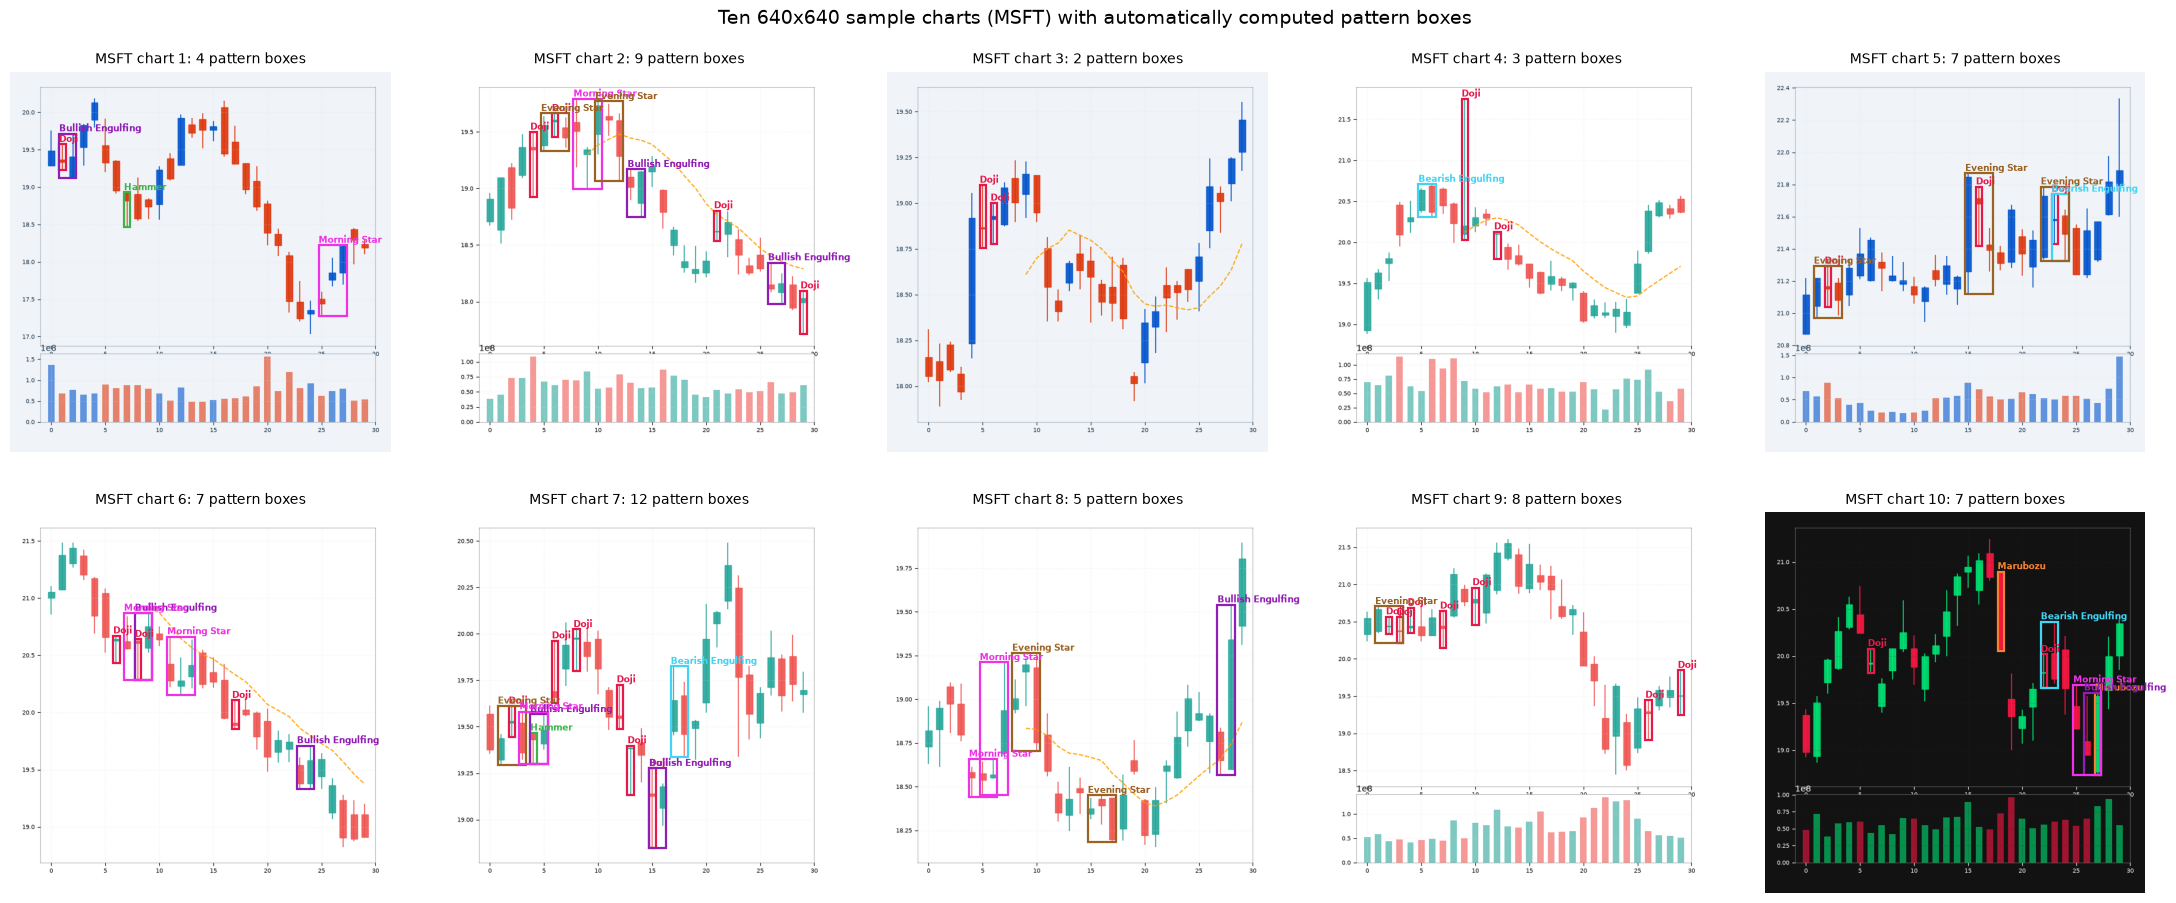

In [9]:
# Task 1.3: Render 10 sample charts with superimposed pattern boxes
# The boxes are read back from the YOLO label files written by the renderer
# (class, x_center, y_center, width, height, all normalised to the 640x640 image).
sample_ticker = set_a_symbols[0]
sample_df = df_stocks[df_stocks['symbol'] == sample_ticker].sort_values('date').reset_index(drop=True)
box_colors = ['#e6194b', '#3cb44b', '#4363d8', '#f58231', '#911eb4', '#42d4f4', '#f032e6', '#9a6324']

fig, axes = plt.subplots(2, 5, figsize=(22, 9.5))
axes = axes.flatten()

for idx in range(10):
    start_idx = 100 + idx * 35
    window_data = sample_df.iloc[start_idx:start_idx+30]
    img_path = f"results/demo_chart_{idx}.png"
    lbl_path = f"results/demo_label_{idx}.txt"
    pats = render_chart_with_annotations(window_data, img_path, lbl_path)

    img = Image.open(img_path).convert('RGB')
    W, H = img.size
    axes[idx].imshow(img)
    n_boxes = 0
    if os.path.exists(lbl_path):
        with open(lbl_path) as stream:
            for line in stream:
                if not line.strip():
                    continue
                cls, xc, yc, bw, bh = line.split()
                cls = int(cls)
                xc, yc, bw, bh = float(xc) * W, float(yc) * H, float(bw) * W, float(bh) * H
                axes[idx].add_patch(patches.Rectangle((xc - bw / 2, yc - bh / 2), bw, bh, fill=False,
                                                      edgecolor=box_colors[cls], linewidth=1.6))
                axes[idx].text(xc - bw / 2, yc - bh / 2 - 4, PATTERN_CLASSES[cls], color=box_colors[cls],
                               fontsize=6.5, fontweight='bold')
                n_boxes += 1
    axes[idx].set_title(f"{sample_ticker} chart {idx+1}: {n_boxes} pattern boxes", fontsize=10)
    axes[idx].axis('off')

fig.suptitle(f"Ten 640x640 sample charts ({sample_ticker}) with automatically computed pattern boxes", fontsize=14)
fig.tight_layout()
fig.savefig("report/figures/sample_10_charts.png", dpi=200)
display(fig)
plt.close(fig)


## 4. Dataset Generation (Train, Val, Test, Recent)
Following project specifications:
- **Train (2010–2017)**: $\ge 3,000$ randomly selected 30-day windows across the 12 Set A tickers.
- **Validation (2018)**: $\ge 500$ synchronized windows across all 12 tickers (window ending every 4 trading days).
- **Test (2019–2020)**: $\ge 500$ synchronized windows across all 12 tickers (window ending every 4 trading days).
- **Recent (2023–2024)**: $\ge 500$ synchronized windows across all 12 tickers.
- **Trend Label**: `next_day_up = 1` if Close($t+1$) > Close($t$), else 0.
- Output directory format: Standard YOLO dataset structure (`images/train`, `labels/train`, etc.) and accompanying CSV index files for the CNN.


In [10]:
# Dataset Generation Pipeline (Optimized with pre-grouping, Agg backend & zero warnings)
import warnings
warnings.filterwarnings('ignore')
import matplotlib
matplotlib.use('Agg')
plt.ioff()

if 'set_a_symbols' not in globals():
    set_a_symbols = ['MSFT', 'NVDA', 'INTC', 'CSCO', 'BAC', 'GS', 'MS', 'WFC', 'PFE', 'UNH', 'ABT', 'CAT']

def generate_datasets_split(df_all_stocks, set_a_symbols):
    splits = {
        'train': ('2010-01-01', '2017-12-31'),
        'val': ('2018-01-01', '2018-12-31'),
        'test': ('2019-01-01', '2020-12-31'),
        'recent': ('2023-01-01', '2024-12-31')
    }
    
    dataset_records = {s: [] for s in splits}
    yolo_root = "yolo_dataset"
    os.makedirs(yolo_root, exist_ok=True)
    
    # Check if already generated
    if os.path.exists(f"{yolo_root}/dataset.yaml"):
        print(f"YOLO dataset already generated at {yolo_root}.")
        return
        
    print("Beginning synchronized chart rendering for Train, Val, Test, Recent...")
    for split_name, (s_date, e_date) in splits.items():
        img_dir = f"{yolo_root}/images/{split_name}"
        lbl_dir = f"{yolo_root}/labels/{split_name}"
        os.makedirs(img_dir, exist_ok=True)
        os.makedirs(lbl_dir, exist_ok=True)
        
        split_stocks = df_all_stocks[(df_all_stocks['date'] >= s_date) & (df_all_stocks['date'] <= e_date)]
        unique_dates = sorted(split_stocks['date'].unique())
        
        # Pre-group by symbol ONCE for 100x speedup
        sym_dict = {
            sym: split_stocks[split_stocks['symbol'] == sym].sort_values('date').reset_index(drop=True)
            for sym in set_a_symbols
        }
        
        if split_name == 'train':
            # Generate >= 3,000 random windows across the 12 tickers
            total_target = 3000
            for i in range(total_target):
                sym = random.choice(set_a_symbols)
                sym_data = sym_dict[sym]
                if len(sym_data) < 32:
                    continue
                start_i = random.randint(0, len(sym_data) - 32)
                window = sym_data.iloc[start_i:start_i+30]
                next_day = sym_data.iloc[start_i+30]
                
                img_name = f"train_{sym}_{i:05d}.jpg"
                img_p = f"{img_dir}/{img_name}"
                lbl_p = f"{lbl_dir}/{img_name.replace('.jpg', '.txt')}"
                
                next_up = int(next_day['close'] > window.iloc[-1]['close'])
                style_cfg = {
                    'theme': random.choice(['light', 'dark', 'blue-white']),
                    'grid': random.choice([True, False]),
                    'volume': random.choice([True, False]),
                    'sma': random.choice([True, False])
                }
                render_chart_with_annotations(window, img_p, lbl_p, style_cfg=style_cfg)
                
                dataset_records[split_name].append({
                    'image_path': img_p,
                    'symbol': sym,
                    'end_date': window.iloc[-1]['date'],
                    'next_date': next_day['date'],
                    'next_day_up': next_up,
                    'theme': style_cfg['theme']
                })
                
                if (i + 1) % 500 == 0 or (i + 1) == total_target:
                    print(f"  [Train] Rendered {i + 1}/{total_target} charts...")
        else:
            # Synchronized windows every 4 trading days across all 12 tickers
            step = 4
            count = 0
            for d_idx in range(30, len(unique_dates) - 1, step):
                target_date = unique_dates[d_idx]
                for sym in set_a_symbols:
                    sym_data = sym_dict[sym]
                    match_idx = sym_data[sym_data['date'] == target_date].index
                    if len(match_idx) == 0 or match_idx[0] < 29 or match_idx[0] + 1 >= len(sym_data):
                        continue
                    end_pos = match_idx[0]
                    window = sym_data.iloc[end_pos-29:end_pos+1]
                    next_day = sym_data.iloc[end_pos+1]
                    
                    img_name = f"{split_name}_{sym}_{count:05d}.jpg"
                    img_p = f"{img_dir}/{img_name}"
                    lbl_p = f"{lbl_dir}/{img_name.replace('.jpg', '.txt')}"
                    
                    next_up = int(next_day['close'] > window.iloc[-1]['close'])
                    style_cfg = {
                        'theme': random.choice(['light', 'dark', 'blue-white']),
                        'grid': random.choice([True, False]),
                        'volume': random.choice([True, False]),
                        'sma': random.choice([True, False])
                    }
                    render_chart_with_annotations(window, img_p, lbl_p, style_cfg=style_cfg)
                    
                    dataset_records[split_name].append({
                        'image_path': img_p,
                        'symbol': sym,
                        'end_date': window.iloc[-1]['date'],
                        'next_date': next_day['date'],
                        'next_day_up': next_up,
                        'theme': style_cfg['theme']
                    })
                    count += 1
                    
                    if count % 200 == 0:
                        print(f"  [{split_name}] Rendered {count} charts...")
                    
        pd.DataFrame(dataset_records[split_name]).to_csv(f"results/{split_name}_metadata.csv", index=False)
        print(f"Generated {len(dataset_records[split_name])} charts for split '{split_name}'.")

    # Write dataset.yaml for Ultralytics YOLO
    yaml_content = f"""
path: {os.path.abspath(yolo_root)}
train: images/train
val: images/val
test: images/test
recent: images/recent

names:
  0: Doji
  1: Hammer
  2: Shooting Star
  3: Marubozu
  4: Bullish Engulfing
  5: Bearish Engulfing
  6: Morning Star
  7: Evening Star
"""
    with open(f"{yolo_root}/dataset.yaml", 'w') as f:
        f.write(yaml_content.strip())
    print(f"Dataset config written to {yolo_root}/dataset.yaml")

# Run generation
generate_datasets_split(df_stocks, set_a_symbols)


YOLO dataset already generated at yolo_dataset.


 train:  3000 label files,  2995 with at least one box,  20061 boxes
   val:   660 label files,   660 with at least one box,   4568 boxes


  test:  1428 label files,  1419 with at least one box,   9218 boxes
recent:  1416 label files,  1415 with at least one box,   9144 boxes
                   train   val  test  recent  train_share_%
Pattern                                                    
Doji                9624  2201  4025    4376           48.0
Hammer               511    99   294     144            2.5
Shooting Star        494    88   230     197            2.5
Marubozu            1405   376   723     642            7.0
Bullish Engulfing   1411   226   834     628            7.0
Bearish Engulfing   2131   498  1049    1091           10.6
Morning Star        2212   538   928    1004           11.0
Evening Star        2273   542  1135    1062           11.3


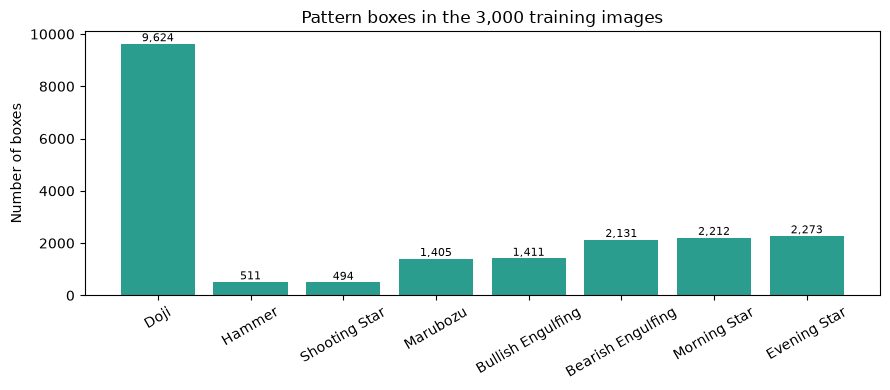

In [11]:
# Task 1.3 (EDA item 3): how often each of the 8 patterns occurs, counted from the YOLO label files
# (one line per pattern box) that the renderer wrote for every split.
split_counts = {}
for split in ['train', 'val', 'test', 'recent']:
    counts = np.zeros(len(PATTERN_CLASSES), dtype=int)
    images_with_box = 0
    label_files = glob.glob(f"yolo_dataset/labels/{split}/*.txt")
    for label_path in label_files:
        with open(label_path) as stream:
            lines = [line for line in stream if line.strip()]
        images_with_box += bool(lines)
        for line in lines:
            counts[int(line.split()[0])] += 1
    split_counts[split] = counts
    print(f"{split:>6}: {len(label_files):5d} label files, {images_with_box:5d} with at least one box, {counts.sum():6d} boxes")

pattern_counts = pd.DataFrame(split_counts, index=PATTERN_CLASSES)
pattern_counts['train_share_%'] = (100 * pattern_counts['train'] / pattern_counts['train'].sum()).round(1)
pattern_counts.index.name = 'Pattern'
pattern_counts.to_csv("results/pattern_counts.csv")
print(pattern_counts.to_string())

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(PATTERN_CLASSES, pattern_counts['train'], color='#2a9d8f')
ax.bar_label(bars, labels=[f"{c:,}" for c in pattern_counts['train']], fontsize=8)
ax.set_title(f"Pattern boxes in the {len(glob.glob('yolo_dataset/labels/train/*.txt')):,} training images")
ax.set_ylabel("Number of boxes")
ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
fig.savefig("report/figures/pattern_distribution.png", dpi=200)
display(fig)
plt.close(fig)


## 5. Task 2: Candlestick Pattern Detection with YOLOv8
We train `yolov8n.yaml` strictly **from scratch** (no pretrained `.pt` weights allowed).
We compare three distinct augmentation configurations:
- **Run A**: Zero Augmentation (`hsv_h=0, hsv_s=0, hsv_v=0, degrees=0, translate=0, scale=0, shear=0, perspective=0, flipud=0, fliplr=0, mosaic=0, mixup=0`).
- **Run B**: Standard Vision Augmentation (`fliplr=0.5, flipud=0.2, mosaic=1.0, degrees=10.0, shear=2.0, hsv_s=0.5, hsv_v=0.4`).
- **Run C**: Domain-Suited Chart Augmentation (`hsv_v=0.2, scale=0.05, translate=0.02`, zero vertical/horizontal flips, noise/brightness preserved).


In [12]:
# YOLOv8 Training Setup
from ultralytics import YOLO

dataset_yaml_path = os.path.abspath("yolo_dataset/dataset.yaml")

def train_yolo_run(run_name, aug_kwargs, epochs=25, imgsz=640, batch=16):
    print(f"\n================ Starting YOLO Training: {run_name} ================")
    # Initialize from yaml configuration strictly (NO PRETRAINED WEIGHTS)
    model = YOLO("yolov8n.yaml")
    
    # Train
    results = model.train(
        data=dataset_yaml_path,
        name=run_name,
        epochs=epochs,
        imgsz=imgsz,
        batch=batch,
        seed=SEED,
        device=0 if torch.cuda.is_available() else 'cpu',
        plots=True,
        save=True,
        amp=False, # Disable AMP to prevent downloading check checkpoint
        **aug_kwargs
    )
    return model, results

# Run A Augmentations: None
aug_run_a = dict(
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,
    degrees=0.0, translate=0.0, scale=0.0, shear=0.0, perspective=0.0,
    flipud=0.0, fliplr=0.0, mosaic=0.0, mixup=0.0, copy_paste=0.0
)

# Run B Augmentations: Standard Vision
aug_run_b = dict(
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    degrees=10.0, translate=0.1, scale=0.2, shear=2.0, perspective=0.0,
    flipud=0.2, fliplr=0.5, mosaic=1.0, mixup=0.1, copy_paste=0.0
)

# Run C Augmentations: Domain-Specific Chart Safe
aug_run_c = dict(
    hsv_h=0.0, hsv_s=0.1, hsv_v=0.2, # Gentle brightness & contrast shifts
    degrees=0.0, translate=0.02, scale=0.05, shear=0.0, perspective=0.0, # Slight shift/scale
    flipud=0.0, fliplr=0.0, mosaic=0.0, mixup=0.0, copy_paste=0.0 # Strict zero flips
)

# Train all three runs (20 epochs each on a Kaggle T4 in the original experiment).
# Training from scratch takes hours on a small GPU, so when the submitted weights
# checkpoints/yolo_best.pt (Run C, the validation-selected run) already exist they are reused.
# Set RETRAIN_YOLO=1 to train Runs A, B and C again from yolov8n.yaml.
RETRAIN_YOLO = os.environ.get("RETRAIN_YOLO") == "1" or not os.path.exists("checkpoints/yolo_best.pt")
if RETRAIN_YOLO:
    model_a, res_a = train_yolo_run("Run_A_No_Aug", aug_run_a, epochs=20)
    model_b, res_b = train_yolo_run("Run_B_Standard_Aug", aug_run_b, epochs=20)
    model_c, res_c = train_yolo_run("Run_C_Chart_Aug", aug_run_c, epochs=20)
else:
    model_a = model_b = model_c = None
    print("Reusing checkpoints/yolo_best.pt (Run C). Set RETRAIN_YOLO=1 to retrain Runs A, B and C.")


Reusing checkpoints/yolo_best.pt (Run C). Set RETRAIN_YOLO=1 to retrain Runs A, B and C.


In [13]:
# Select the best run on validation, then evaluate test once
if RETRAIN_YOLO:
    yolo_eval_summary = []
    run_models = [("Run_A_No_Aug", model_a), ("Run_B_Standard_Aug", model_b), ("Run_C_Chart_Aug", model_c)]
    for run_name, model in run_models:
        val_metrics = model.val(data=dataset_yaml_path, split='val')
        metrics = model.val(data=dataset_yaml_path, split='test')
        yolo_eval_summary.append({
            'Run': run_name, 'Source': 'measured in this run',
            'Validation mAP@50-95': val_metrics.box.map,
            'Precision': metrics.box.mp, 'Recall': metrics.box.mr,
            'mAP@50': metrics.box.map50, 'mAP@50-95': metrics.box.map
        })
    df_yolo_comp = pd.DataFrame(yolo_eval_summary)
    # Identify the best run without consulting test performance.
    best_run = df_yolo_comp.sort_values('Validation mAP@50-95', ascending=False).iloc[0]['Run']
    shutil.copy(f"runs/detect/{best_run}/weights/best.pt", "checkpoints/yolo_best.pt")
else:
    # Runs A and B were trained on Kaggle and only the selected Run C weights were kept, so their
    # test metrics come from the recorded Kaggle evaluation (results/detection_results_kaggle_runs.csv).
    # Run C is re-evaluated here from checkpoints/yolo_best.pt on the charts generated above.
    best_run = 'Run_C_Chart_Aug'
    recorded = pd.read_csv("results/detection_results_kaggle_runs.csv")
    model_c = YOLO("checkpoints/yolo_best.pt")
    val_metrics = model_c.val(data=dataset_yaml_path, split='val', batch=16, plots=False)
    metrics = model_c.val(data=dataset_yaml_path, split='test', batch=16, plots=False)
    rows = []
    for _, r in recorded.iterrows():
        if r['Run'] == best_run:
            rows.append({'Run': best_run, 'Source': 'measured in this run (yolo_best.pt)',
                         'Validation mAP@50-95': val_metrics.box.map,
                         'Precision': metrics.box.mp, 'Recall': metrics.box.mr,
                         'mAP@50': metrics.box.map50, 'mAP@50-95': metrics.box.map})
        else:
            rows.append({'Run': r['Run'], 'Source': 'recorded Kaggle evaluation (weights not kept)',
                         'Validation mAP@50-95': np.nan, 'Precision': r['Precision'], 'Recall': r['Recall'],
                         'mAP@50': r['mAP@50'], 'mAP@50-95': r['mAP@50-95']})
    df_yolo_comp = pd.DataFrame(rows)

df_yolo_comp.to_csv("results/detection_results.csv", index=False)
print("--- YOLOv8 Test Split Evaluation Summary ---")
with pd.option_context('display.width', 200, 'display.max_columns', None):
    print(df_yolo_comp.to_string(index=False))
print()
print(f"Best YOLO Run (selected on validation mAP@50-95): {best_run}")


Ultralytics 8.4.218  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)


YOLOv8n summary (fused): 72 layers, 3,007,208 parameters, 0 gradients, 8.1 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 260.0±33.8 MB/s, size: 28.5 KB)


val: Scanning C:\Users\Hp\cs4045-project\yolo_dataset\labels\val.cache... 660 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 660/660  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 2% ──────────── 1/42 81.3s/it 24.4s<55:35

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 4% ╸─────────── 2/42 1.6it/s 24.6s<24.8s

... (160 outputs left out)

          Evening Star        846       1135      0.732      0.766      0.822      0.713


Speed: 1.9ms preprocess, 5.9ms inference, 0.0ms loss, 1.8ms postprocess per image


--- YOLOv8 Test Split Evaluation Summary ---


               Run                                        Source  Validation mAP@50-95  Precision   Recall   mAP@50  mAP@50-95
      Run_A_No_Aug recorded Kaggle evaluation (weights not kept)                   NaN   0.534643 0.603460 0.574456   0.479010
Run_B_Standard_Aug recorded Kaggle evaluation (weights not kept)                   NaN   0.488972 0.606856 0.553369   0.442984
   Run_C_Chart_Aug           measured in this run (yolo_best.pt)              0.585688   0.595320 0.666470 0.665798   0.586005

Best YOLO Run (selected on validation mAP@50-95): Run_C_Chart_Aug


Ultralytics 8.4.218  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)


YOLOv8n summary (fused): 72 layers, 3,007,208 parameters, 0 gradients, 8.1 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 2.2±0.6 MB/s, size: 12.1 KB)


val: Scanning C:\Users\Hp\cs4045-project\yolo_dataset\labels\test_robust_480... 38 images, 0 backgrounds, 0 corrupt: 2% ──────────── 38/1428 109.6it/s 0.1s<12.7s

val: Scanning C:\Users\Hp\cs4045-project\yolo_dataset\labels\test_robust_480... 81 images, 0 backgrounds, 0 corrupt: 5% ╸─────────── 81/1428 198.6it/s 0.2s<6.8s

val: Scanning C:\Users\Hp\cs4045-project\yolo_dataset\labels\test_robust_480... 124 images, 0 backgrounds, 0 corrupt: 8% ━─────────── 124/1428 262.0it/s 0.3s<5.0s

... (233 outputs left out)

          Evening Star        846       1135      0.732      0.766      0.822      0.713


Speed: 1.5ms preprocess, 5.9ms inference, 0.0ms loss, 1.7ms postprocess per image


Results saved to C:\Users\Hp\cs4045-project\runs\detect\val-44


Test-set confusion matrix copied from C:\Users\Hp\cs4045-project\runs\detect\val-44\confusion_matrix_normalized.png

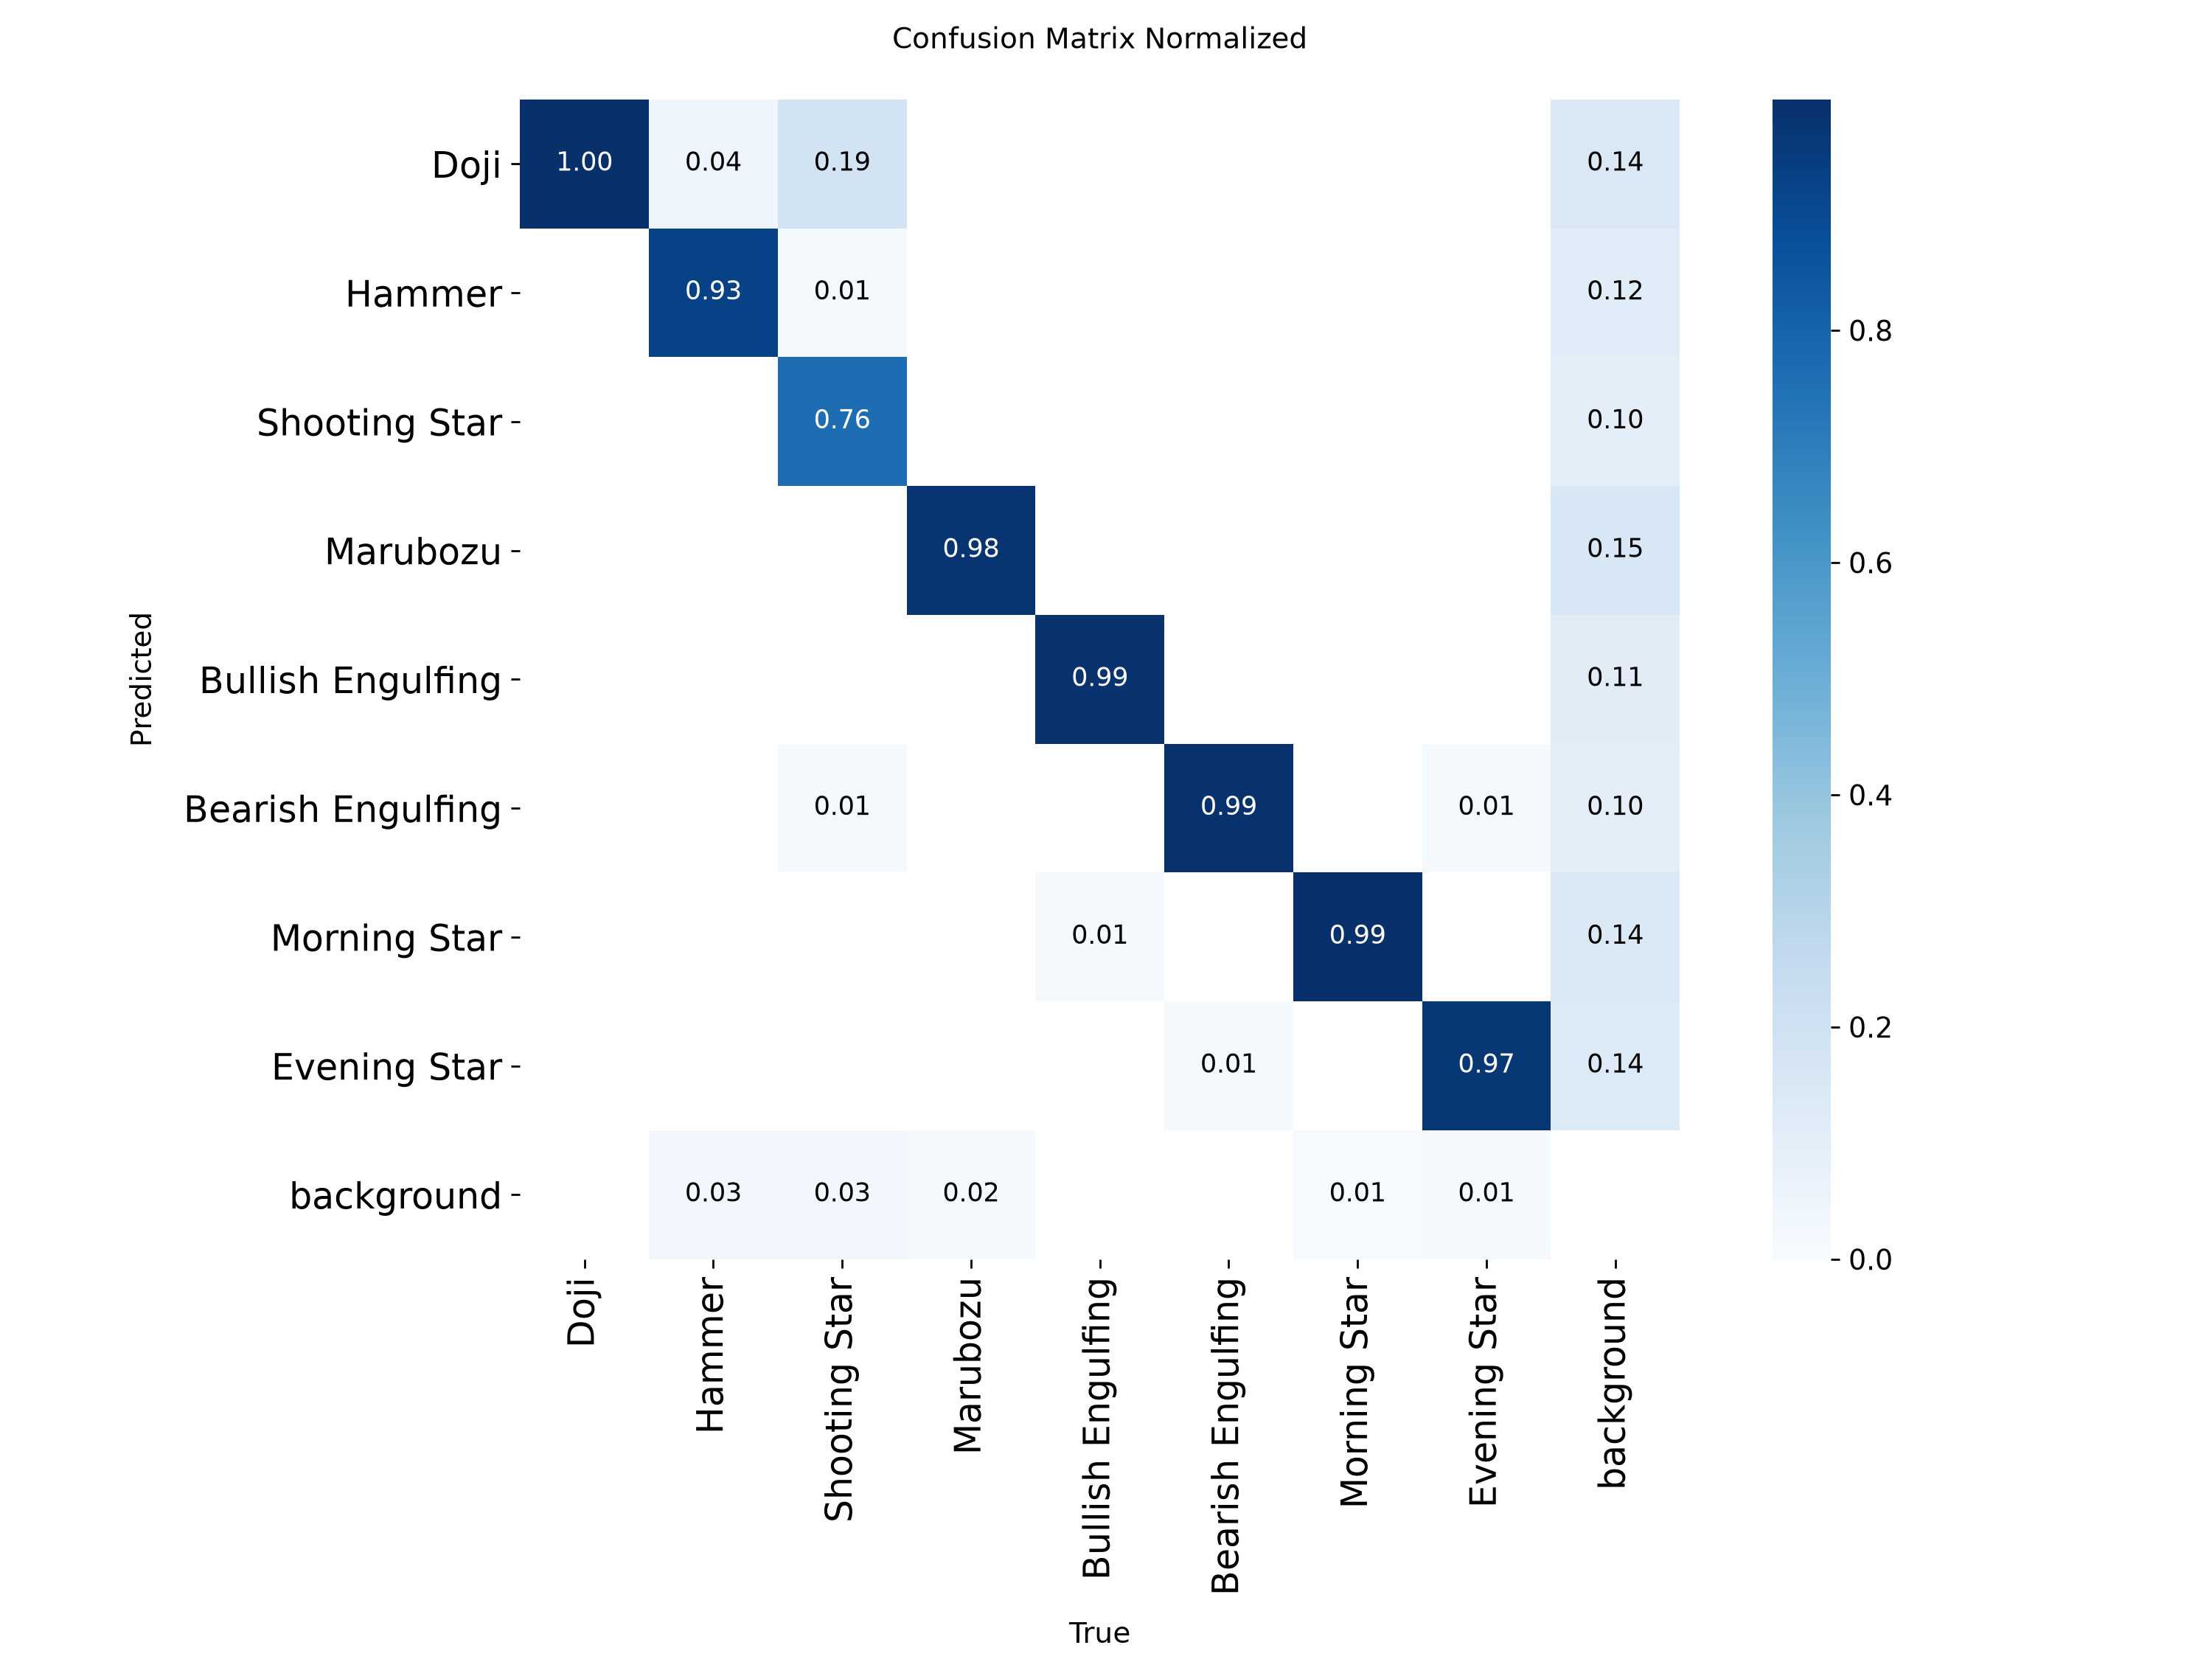

            Class  Test Boxes  Precision   Recall   mAP@50  mAP@50-95
             Doji        4025   0.810711 0.958261 0.959262   0.869112
           Hammer         294   0.400167 0.384354 0.376967   0.328805
    Shooting Star         230   0.335792 0.307731 0.254508   0.222846
         Marubozu         723   0.450123 0.520818 0.485981   0.413794
Bullish Engulfing         834   0.665306 0.777008 0.790711   0.690872
Bearish Engulfing        1049   0.694266 0.822688 0.832787   0.752414
     Morning Star         928   0.674159 0.795259 0.804148   0.697050
     Evening Star        1135   0.732032 0.765639 0.822021   0.713149
Ultralytics 8.4.218  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)


YOLOv8n summary (fused): 72 layers, 3,007,208 parameters, 0 gradients, 8.1 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 259.8±34.2 MB/s, size: 28.4 KB)


val: Scanning C:\Users\Hp\cs4045-project\yolo_dataset\labels\test... 175 images, 4 backgrounds, 0 corrupt: 33% ━━━╸──────── 175/526 490.0it/s 0.1s<0.7s

val: Scanning C:\Users\Hp\cs4045-project\yolo_dataset\labels\test... 362 images, 4 backgrounds, 0 corrupt: 68% ━━━━━━━━──── 362/526 863.4it/s 0.2s<0.2s

val: Scanning C:\Users\Hp\cs4045-project\yolo_dataset\labels\test... 526 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 526/526 1.8Kit/s 0.3s

... (239 outputs left out)

          Evening Star        845       1062      0.722       0.76      0.808        0.7


Speed: 1.6ms preprocess, 6.0ms inference, 0.0ms loss, 1.6ms postprocess per image


Results saved to C:\Users\Hp\cs4045-project\runs\detect\val-48


Evaluation   mAP@50
     light 0.664987
      dark 0.673315
blue-white 0.669421
    recent 0.673291


In [14]:
# Task 2.3 Robustness Check: Resize to 480x480 & apply JPEG compression
import cv2

best_model = YOLO("checkpoints/yolo_best.pt")
test_imgs = glob.glob("yolo_dataset/images/test/*.jpg")

robust_dir = "yolo_dataset/images/test_robust_480"
robust_label_dir = "yolo_dataset/labels/test_robust_480"
os.makedirs(robust_dir, exist_ok=True)
os.makedirs(robust_label_dir, exist_ok=True)

for p in test_imgs:
    img = cv2.imread(p)
    # Resize to 480x480
    resized = cv2.resize(img, (480, 480))
    # Save as lower quality JPEG (quality=40)
    out_p = os.path.join(robust_dir, os.path.basename(p))
    cv2.imwrite(out_p, resized, [int(cv2.IMWRITE_JPEG_QUALITY), 40])
    source_label = p.replace('images', 'labels').replace('.jpg', '.txt')
    shutil.copy2(source_label, os.path.join(robust_label_dir, os.path.basename(source_label)))

robust_yaml_path = os.path.abspath("yolo_dataset/robust_dataset.yaml")
with open(robust_yaml_path, 'w') as stream:
    stream.write(f'''path: {os.path.abspath('yolo_dataset')}
train: images/train
val: images/val
test: images/test_robust_480
names: {{0: Doji, 1: Hammer, 2: Shooting Star, 3: Marubozu, 4: Bullish Engulfing, 5: Bearish Engulfing, 6: Morning Star, 7: Evening Star}}
''')

robust_metrics = best_model.val(batch=16, data=robust_yaml_path, split='test', imgsz=480)
best_test_map50 = df_yolo_comp.loc[df_yolo_comp['Run'] == best_run, 'mAP@50'].iloc[0]
robustness = pd.DataFrame([{
    'Best Run': best_run, 'Original mAP@50': best_test_map50,
    'Robust mAP@50': robust_metrics.box.map50,
    'Absolute Drop': best_test_map50 - robust_metrics.box.map50
}])
robustness.to_csv("results/detection_robustness.csv", index=False)
print(robustness.to_string(index=False))

# Per-class test metrics and test-box counts for the validation-selected run.
test_metrics = best_model.val(batch=16, data=dataset_yaml_path, split='test')
# Ultralytics writes the confusion matrix of this test evaluation into its save directory.
cm_dir = getattr(test_metrics, 'save_dir', None)
cm_candidates = sorted(glob.glob(os.path.join(str(cm_dir), 'confusion_matrix_normalized.png'))) if cm_dir else []
if not cm_candidates:
    cm_candidates = sorted(glob.glob('runs/detect/val*/confusion_matrix_normalized.png'), key=os.path.getmtime)[-1:]
if cm_candidates:
    shutil.copy(cm_candidates[-1], 'report/figures/yolo_confusion_matrix.png')
    print(f"Test-set confusion matrix copied from {cm_candidates[-1]}")
    display(Image.open('report/figures/yolo_confusion_matrix.png'))
box_counts = np.zeros(8, dtype=int)
for label_path in glob.glob("yolo_dataset/labels/test/*.txt"):
    with open(label_path) as stream:
        for line in stream:
            if line.strip():
                box_counts[int(line.split()[0])] += 1
class_names = ['Doji', 'Hammer', 'Shooting Star', 'Marubozu', 'Bullish Engulfing', 'Bearish Engulfing', 'Morning Star', 'Evening Star']
per_class = pd.DataFrame({
    'Class': class_names, 'Test Boxes': box_counts,
    'Precision': test_metrics.box.p, 'Recall': test_metrics.box.r,
    'mAP@50': test_metrics.box.ap50, 'mAP@50-95': test_metrics.box.maps
})
per_class.to_csv("results/detection_per_class.csv", index=False)
print(per_class.to_string(index=False))

pd.DataFrame([{
    'Best Run': best_run,
    'Inference (ms/image)': test_metrics.speed.get('inference', np.nan),
    'Checkpoint Size (MB)': os.path.getsize('checkpoints/yolo_best.pt') / (1024 ** 2)
}]).to_csv("results/detection_efficiency.csv", index=False)

# Theme and recent-set evaluation using recorded generation metadata.
theme_rows = []
test_metadata = pd.read_csv("results/test_metadata.csv")
for theme in ['light', 'dark', 'blue-white']:
    image_list = os.path.abspath(f"results/test_{theme}_images.txt")
    with open(image_list, 'w') as stream:
        stream.write('\n'.join(os.path.abspath(p) for p in test_metadata.loc[test_metadata['theme'] == theme, 'image_path']))
    themed_yaml = os.path.abspath(f"yolo_dataset/{theme}_dataset.yaml")
    with open(themed_yaml, 'w') as stream:
        stream.write(f'''path: {os.path.abspath('yolo_dataset')}
train: images/train
val: images/val
test: {image_list}
names: {{0: Doji, 1: Hammer, 2: Shooting Star, 3: Marubozu, 4: Bullish Engulfing, 5: Bearish Engulfing, 6: Morning Star, 7: Evening Star}}
''')
    theme_metrics = best_model.val(batch=16, data=themed_yaml, split='test')
    theme_rows.append({'Evaluation': theme, 'mAP@50': theme_metrics.box.map50})
recent_image_list = os.path.abspath("results/recent_images.txt")
with open(recent_image_list, 'w') as stream:
    stream.write('\n'.join(os.path.abspath(p) for p in glob.glob("yolo_dataset/images/recent/*.jpg")))
recent_yaml = os.path.abspath("yolo_dataset/recent_dataset.yaml")
with open(recent_yaml, 'w') as stream:
    stream.write(f'''path: {os.path.abspath('yolo_dataset')}
train: images/train
val: images/val
test: {recent_image_list}
names: {{0: Doji, 1: Hammer, 2: Shooting Star, 3: Marubozu, 4: Bullish Engulfing, 5: Bearish Engulfing, 6: Morning Star, 7: Evening Star}}
''')
recent_metrics = best_model.val(batch=16, data=recent_yaml, split='test')
theme_rows.append({'Evaluation': 'recent', 'mAP@50': recent_metrics.box.map50})
pd.DataFrame(theme_rows).to_csv("results/detection_theme_results.csv", index=False)
print(pd.DataFrame(theme_rows).to_string(index=False))


Test images: 1428 | images with no error: 49 | total missed: 1385 | total false positives: 3774
Most often missed classes: [('Marubozu', 329), ('Evening Star', 191), ('Morning Star', 167), ('Hammer', 159)]
Most common false-positive classes: [('Doji', 1165), ('Marubozu', 534), ('Bearish Engulfing', 467), ('Morning Star', 447)]


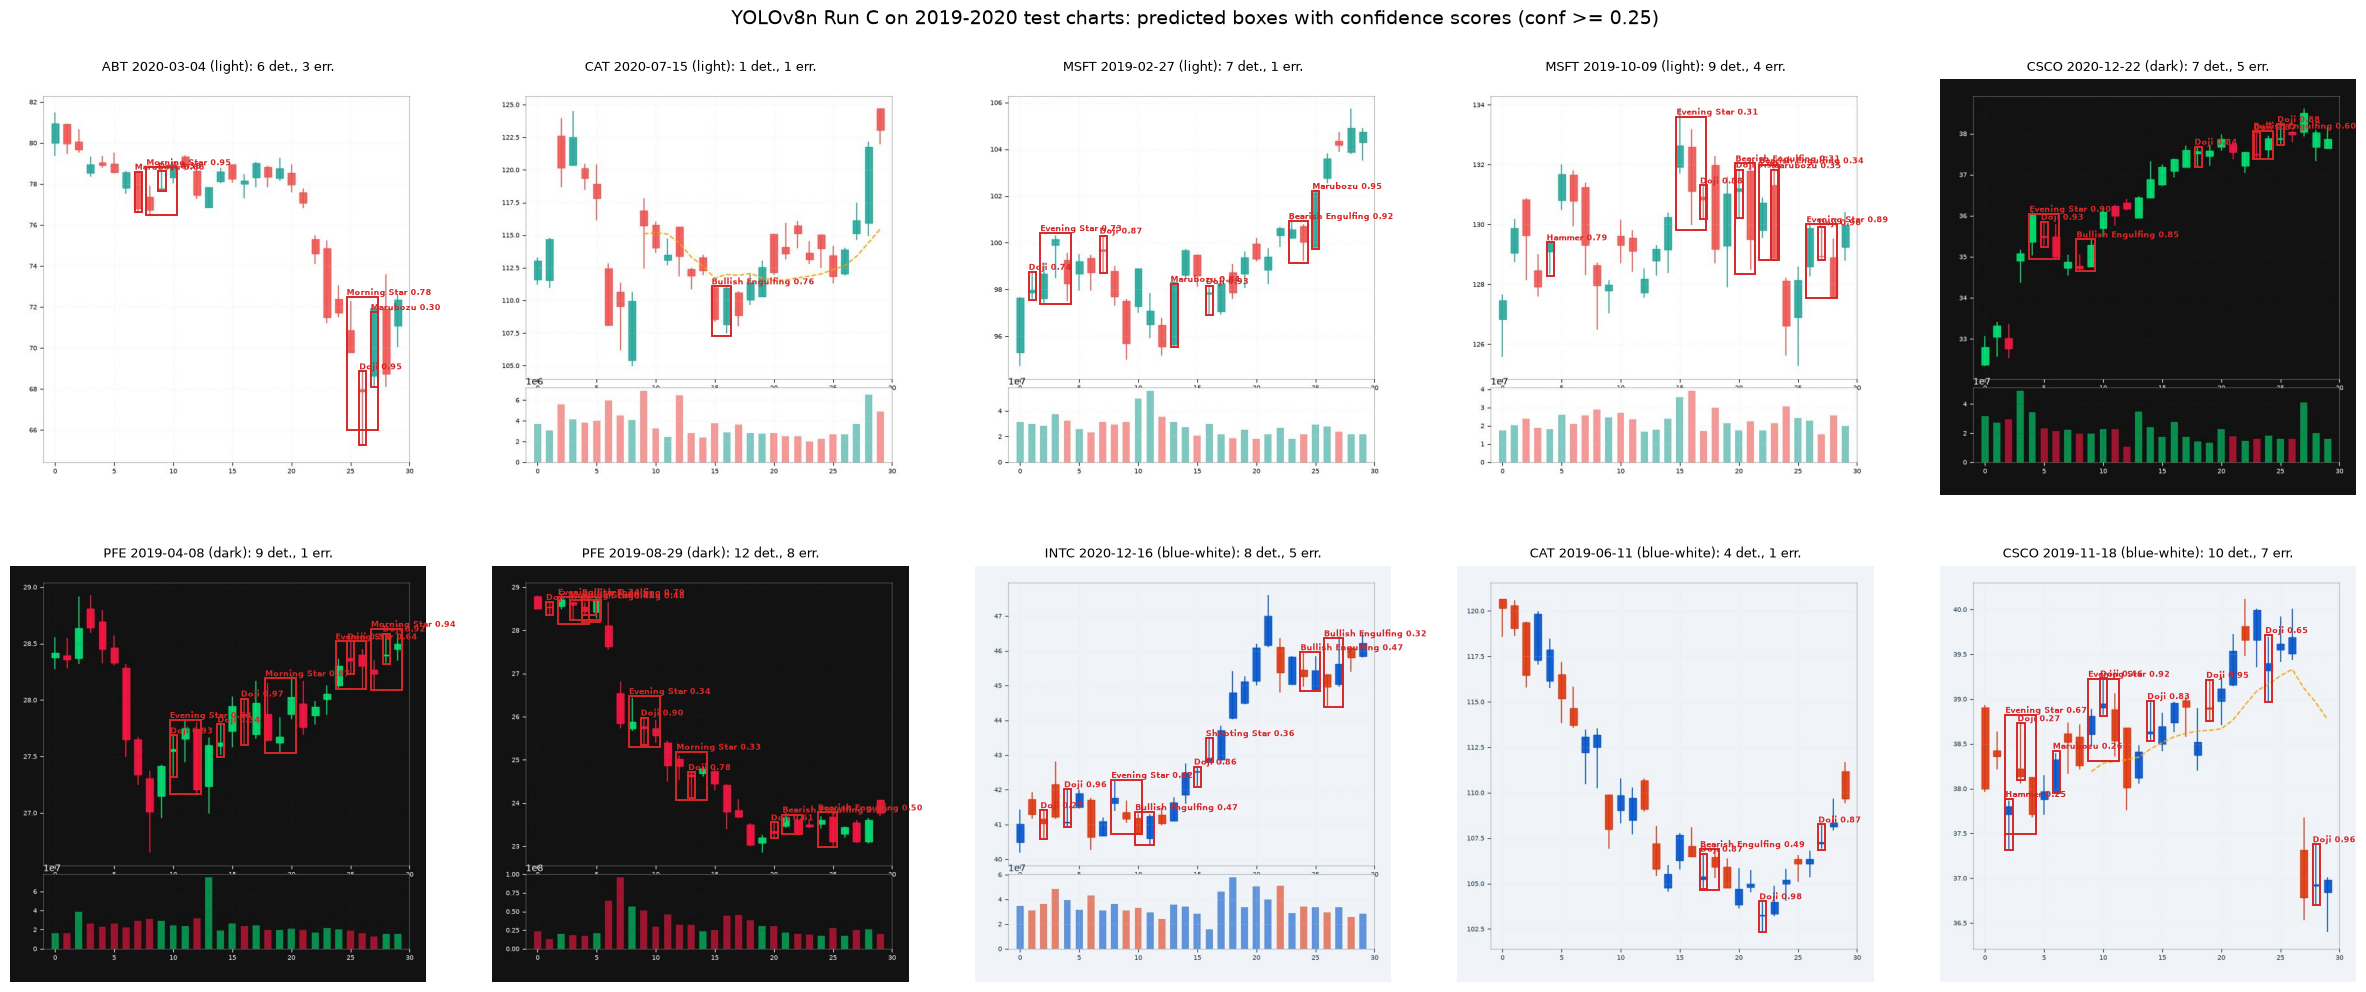

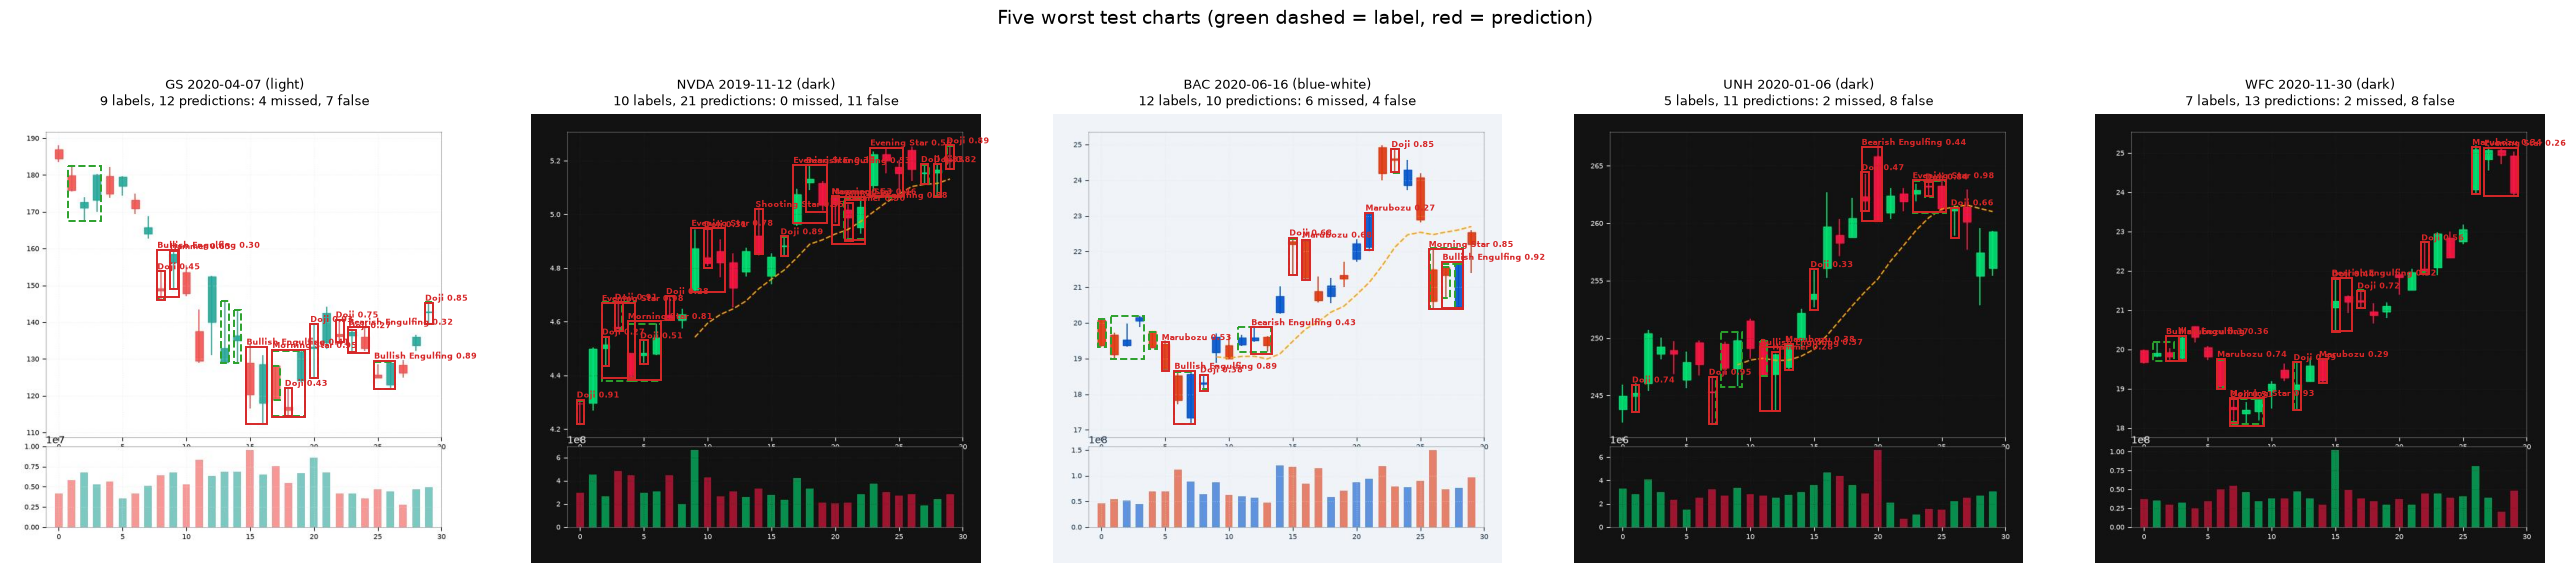

symbol   end_date      theme  gt_boxes  pred_boxes  missed  false_pos                                              missed_classes                                                                                        false_pos_classes
    GS 2020-04-07      light         9          12       4          7                    Shooting Star;Doji;Marubozu;Morning Star                              Doji;Hammer;Doji;Bullish Engulfing;Bearish Engulfing;Bullish Engulfing;Doji
  NVDA 2019-11-12       dark        10          21       0         11                                                             Evening Star;Bearish Engulfing;Hammer;Doji;Morning Star;Evening Star;Shooting Star;Doji;Hammer;Doji;Doji
   BAC 2020-06-16 blue-white        12          10       6          4 Marubozu;Marubozu;Hammer;Marubozu;Morning Star;Evening Star                                                             Marubozu;Marubozu;Bearish Engulfing;Marubozu
   UNH 2020-01-06       dark         5          11       2  

In [15]:
# Task 2.3 / Task 4.4: detections with confidence scores on test images, and the 5 worst test images (failure cases)
from collections import Counter

gallery_model = YOLO("checkpoints/yolo_best.pt")
test_meta = pd.read_csv("results/test_metadata.csv")

def read_gt(img_path, W, H):
    boxes = []
    lbl = img_path.replace('images', 'labels').rsplit('.', 1)[0] + '.txt'
    if os.path.exists(lbl):
        for line in open(lbl):
            if line.strip():
                c, xc, yc, bw, bh = line.split()
                xc, yc, bw, bh = float(xc) * W, float(yc) * H, float(bw) * W, float(bh) * H
                boxes.append((int(c), xc - bw / 2, yc - bh / 2, xc + bw / 2, yc + bh / 2))
    return boxes

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

def predict(img_path):
    r = gallery_model.predict(img_path, conf=0.25, imgsz=640, verbose=False)[0]
    return [(int(c), *xyxy, float(p)) for xyxy, c, p in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy())]

def match(gt, pred, thr=0.5):
    used, missed = set(), []
    for g in gt:
        best, best_j = 0.0, None
        for j, p in enumerate(pred):
            if j not in used and p[0] == g[0]:
                v = iou(g[1:5], p[1:5])
                if v > best:
                    best, best_j = v, j
        if best >= thr:
            used.add(best_j)
        else:
            missed.append(g)
    false_pos = [p for j, p in enumerate(pred) if j not in used]
    return missed, false_pos

# 1) Evaluate every test image once.
rows = []
for _, r in test_meta.iterrows():
    W, H = Image.open(r['image_path']).size
    gt, pred = read_gt(r['image_path'], W, H), predict(r['image_path'])
    missed, false_pos = match(gt, pred)
    rows.append({'image_path': r['image_path'], 'symbol': r['symbol'], 'end_date': r['end_date'], 'theme': r['theme'],
                 'gt_boxes': len(gt), 'pred_boxes': len(pred), 'missed': len(missed), 'false_pos': len(false_pos),
                 'missed_classes': ';'.join(PATTERN_CLASSES[g[0]] for g in missed),
                 'false_pos_classes': ';'.join(PATTERN_CLASSES[p[0]] for p in false_pos)})
per_image = pd.DataFrame(rows)
per_image['errors'] = per_image['missed'] + per_image['false_pos']
per_image.to_csv("results/yolo_test_per_image_errors.csv", index=False)
print(f"Test images: {len(per_image)} | images with no error: {(per_image['errors'] == 0).sum()} | "
      f"total missed: {per_image['missed'].sum()} | total false positives: {per_image['false_pos'].sum()}")
print("Most often missed classes:", Counter(c for s in per_image['missed_classes'] for c in s.split(';') if c).most_common(4))
print("Most common false-positive classes:", Counter(c for s in per_image['false_pos_classes'] for c in s.split(';') if c).most_common(4))

def draw(ax, img_path, gt=None, pred=None, title=''):
    ax.imshow(Image.open(img_path).convert('RGB'))
    for g in (gt or []):
        ax.add_patch(patches.Rectangle((g[1], g[2]), g[3] - g[1], g[4] - g[2], fill=False, edgecolor='#2ca02c', linewidth=1.4, linestyle='--'))
    for p in (pred or []):
        ax.add_patch(patches.Rectangle((p[1], p[2]), p[3] - p[1], p[4] - p[2], fill=False, edgecolor='#d62728', linewidth=1.4))
        ax.text(p[1], p[2] - 3, f"{PATTERN_CLASSES[p[0]]} {p[5]:.2f}", color='#d62728', fontsize=6, fontweight='bold')
    ax.set_title(title, fontsize=9); ax.axis('off')

# 2) Ten test images (several per theme, fixed seed) with predicted boxes and confidence scores.
sample = pd.concat([per_image[per_image['theme'] == t].sample(n, random_state=SEED)
                    for t, n in [('light', 4), ('dark', 3), ('blue-white', 3)]])
fig, axes = plt.subplots(2, 5, figsize=(24, 10.5))
for ax, (_, r) in zip(axes.flatten(), sample.iterrows()):
    draw(ax, r['image_path'], pred=predict(r['image_path']),
         title=f"{r['symbol']} {r['end_date']} ({r['theme']}): {r['pred_boxes']} det., {r['errors']} err.")
fig.suptitle("YOLOv8n Run C on 2019-2020 test charts: predicted boxes with confidence scores (conf >= 0.25)", fontsize=14)
fig.tight_layout(); fig.savefig("report/figures/yolo_test_detections.png", dpi=170)
display(fig); plt.close(fig)

# 3) Five failure cases: test images with the most missed + false boxes.
worst = per_image.sort_values(['errors', 'missed'], ascending=False).head(5)
fig, axes = plt.subplots(1, 5, figsize=(26, 6.5))
for ax, (_, r) in zip(axes, worst.iterrows()):
    W, H = Image.open(r['image_path']).size
    draw(ax, r['image_path'], gt=read_gt(r['image_path'], W, H), pred=predict(r['image_path']),
         title=f"{r['symbol']} {r['end_date']} ({r['theme']})\n{r['gt_boxes']} labels, {r['pred_boxes']} predictions: {r['missed']} missed, {r['false_pos']} false")
fig.suptitle("Five worst test charts (green dashed = label, red = prediction)", fontsize=14)
fig.tight_layout(); fig.savefig("report/figures/yolo_failure_cases.png", dpi=170)
display(fig); plt.close(fig)
print(worst[['symbol', 'end_date', 'theme', 'gt_boxes', 'pred_boxes', 'missed', 'false_pos', 'missed_classes', 'false_pos_classes']].to_string(index=False))


## 6. Task 3: Next-Day Direction Trend Prediction with CNN
- Input: 30-day candlestick chart image ($640 \times 640$).
- Output: Probability that next day's close > today's close ($next\_day\_up \in \{0, 1\}$).
- Architecture: Custom ResNet18 adapted for 128-dimensional penultimate embedding extraction.
- Baselines:
  1. Majority Class Classifier (more common direction in training years).
  2. Logistic Regression on the past 5 daily returns.
- Statistical Evaluation: 95% Grouped Bootstrap Confidence Interval (1,000 resamples grouped by trading dates).
- Embeddings: Pass 2010–2024 Market Basket charts through the CNN to save `chart_embeddings.npy` (shape $[N, 128]$) and `embedding_index.csv`.


In [16]:
# PyTorch Dataset for Trend CNN
class CandlestickTrendDataset(Dataset):
    def __init__(self, metadata_csv, transform=None):
        self.df = pd.read_csv(metadata_csv)
        self.transform = transform
        
    def __len__(self):
        return len(self.df)
        
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row['image_path']).convert('RGB')
        label = int(row['next_day_up'])
        if self.transform:
            img = self.transform(img)
        return img, label, row['end_date']

trend_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = CandlestickTrendDataset("results/train_metadata.csv", transform=trend_transforms)
val_dataset = CandlestickTrendDataset("results/val_metadata.csv", transform=trend_transforms)
test_dataset = CandlestickTrendDataset("results/test_metadata.csv", transform=trend_transforms)
recent_dataset = CandlestickTrendDataset("results/recent_metadata.csv", transform=trend_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
recent_loader = DataLoader(recent_dataset, batch_size=32, shuffle=False)

# Custom ResNet18 with 128-dim penultimate embedding
class TrendResNet18(nn.Module):
    def __init__(self, embedding_dim=128):
        super(TrendResNet18, self).__init__()
        base_resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        self.features = nn.Sequential(*list(base_resnet.children())[:-1]) # [B, 512, 1, 1]
        self.embedding_head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, embedding_dim),
            nn.BatchNorm1d(embedding_dim),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        self.classifier = nn.Linear(embedding_dim, 2)
        
    def forward(self, x):
        feat = self.features(x)
        embed = self.embedding_head(feat)
        out = self.classifier(embed)
        return out, embed

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
trend_model = TrendResNet18(embedding_dim=128).to(device)
print(f"Trend CNN Architecture loaded on {device}.")


Trend CNN Architecture loaded on cuda.


In [17]:
# Train Trend CNN with Early Stopping
# The submitted checkpoint checkpoints/cnn_trend_best.pt is reused when it exists, so that the
# Part 2 chart embeddings stay consistent with it. Set RETRAIN_TREND=1 to train from scratch again.
if os.path.exists("checkpoints/cnn_trend_best.pt") and os.environ.get("RETRAIN_TREND") != "1":
    print("Using existing checkpoint checkpoints/cnn_trend_best.pt (set RETRAIN_TREND=1 to retrain).")
else:
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(trend_model.parameters(), lr=1e-4, weight_decay=1e-3)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5)

    best_val_loss = float('inf')
    epochs = 15

    for epoch in range(epochs):
        trend_model.train()
        train_loss, train_correct = 0.0, 0
        for imgs, labels, _ in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            logits, _ = trend_model(imgs)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
        
            train_loss += loss.item() * len(labels)
            train_correct += (logits.argmax(1) == labels).sum().item()
        
        trend_model.eval()
        val_loss, val_correct = 0.0, 0
        with torch.no_grad():
            for imgs, labels, _ in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                logits, _ = trend_model(imgs)
                loss = criterion(logits, labels)
                val_loss += loss.item() * len(labels)
                val_correct += (logits.argmax(1) == labels).sum().item()
            
        val_loss /= len(val_dataset)
        scheduler.step(val_loss)
    
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(trend_model.state_dict(), "checkpoints/cnn_trend_best.pt")
        
        print(f"Epoch {epoch+1:02d}/{epochs:02d} | Train Acc: {train_correct/len(train_dataset):.4f} | Val Acc: {val_correct/len(val_dataset):.4f} | Val Loss: {val_loss:.4f}")


Using existing checkpoint checkpoints/cnn_trend_best.pt (set RETRAIN_TREND=1 to retrain).


Training share of up windows: 0.5083 -> majority class = 1


Test images: 1428 | distinct test dates: 119
Recent images: 1416 | distinct recent dates: 118


                                                          0                                    1                       2
Model                               Majority Class Baseline  Logistic Regression (5-Day Returns)  Trend ResNet-18 (Ours)
Test Accuracy                                        0.5119                               0.5385                  0.4881
Test F1 (Up)                                         0.6772                               0.6809                  0.3852
Test ROC-AUC                                            n/a                               0.5671                  0.5024
Test Acc 95% CI (date bootstrap)           [0.4517, 0.5714]                     [0.4839, 0.5917]        [0.4559, 0.5203]
Test Acc minus Majority 95% CI                          n/a                     [0.0014, 0.0574]       [-0.1100, 0.0610]
Test Acc minus Logistic 95% CI           [-0.0574, -0.0014]                                  n/a       [-0.1275, 0.0252]
Recent Accuracy                 

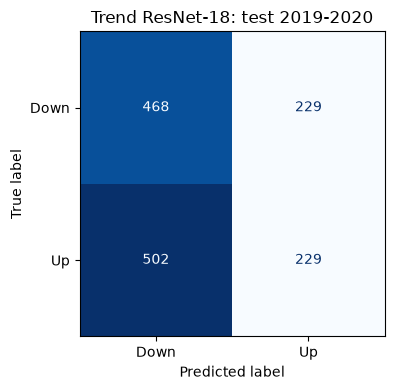

In [18]:
# Evaluate CNN, Baselines & 95% Grouped Bootstrap Confidence Interval (writes results/trend_results.csv)
import time
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression

trend_model.load_state_dict(torch.load("checkpoints/cnn_trend_best.pt", map_location=device))
trend_model.eval()

def predict_split(loader, dataset):
    preds, probs, targets, dates = [], [], [], []
    with torch.no_grad():
        for imgs, labels, batch_dates in loader:
            logits, _ = trend_model(imgs.to(device))
            probs.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            preds.extend(logits.argmax(1).cpu().numpy())
            targets.extend(labels.numpy())
            dates.extend(batch_dates)
    return pd.DataFrame({'date': dates, 'symbol': dataset.df['symbol'].values,
                         'target': targets, 'pred': preds, 'prob': probs})

test_df = predict_split(test_loader, test_dataset)
recent_df = predict_split(recent_loader, recent_dataset)

# 1. Majority-class baseline: the more common direction in the training years.
train_meta = pd.read_csv("results/train_metadata.csv")
majority_class = int(train_meta['next_day_up'].mean() >= 0.5)
print(f"Training share of up windows: {train_meta['next_day_up'].mean():.4f} -> majority class = {majority_class}")

# 2. Logistic regression on the last 5 daily returns of the same ticker (known at the window end date).
returns = df_stocks[['date', 'symbol', 'close']].sort_values(['symbol', 'date']).copy()
returns['daily_return'] = returns.groupby('symbol')['close'].pct_change()
for lag in range(5):
    returns[f'ret_lag_{lag}'] = returns.groupby('symbol')['daily_return'].shift(lag)
return_cols = [f'ret_lag_{lag}' for lag in range(5)]

def attach_return_features(metadata):
    frame = metadata.copy()
    frame['end_date'] = pd.to_datetime(frame['end_date'])
    return frame.merge(returns[['date', 'symbol'] + return_cols],
                       left_on=['end_date', 'symbol'], right_on=['date', 'symbol'], how='left')

train_features = attach_return_features(train_meta)
logit = LogisticRegression(C=1.0, max_iter=2000, random_state=SEED)
logit.fit(train_features[return_cols].fillna(0.0), train_features['next_day_up'])

for frame, ds in [(test_df, test_dataset), (recent_df, recent_dataset)]:
    feats = attach_return_features(ds.df)
    frame['majority_pred'] = majority_class
    frame['logit_prob'] = logit.predict_proba(feats[return_cols].fillna(0.0))[:, 1]
    frame['logit_pred'] = (frame['logit_prob'] >= 0.5).astype(int)

def metrics(frame, pred_col, prob_col):
    acc = accuracy_score(frame['target'], frame[pred_col])
    f1 = f1_score(frame['target'], frame[pred_col], zero_division=0)
    auc = roc_auc_score(frame['target'], frame[prob_col]) if prob_col else np.nan
    return acc, f1, auc

# 3. Bootstrap over whole trading dates (all 12 tickers of a date stay together).
rng = np.random.default_rng(SEED)
def date_bootstrap(frame, n_boot=1000):
    groups = {d: g for d, g in frame.groupby('date')}
    dates = np.array(list(groups))
    acc = {'cnn': [], 'majority': [], 'logit': []}
    for _ in range(n_boot):
        sample = pd.concat([groups[d] for d in rng.choice(dates, size=len(dates), replace=True)])
        acc['cnn'].append(accuracy_score(sample['target'], sample['pred']))
        acc['majority'].append(accuracy_score(sample['target'], sample['majority_pred']))
        acc['logit'].append(accuracy_score(sample['target'], sample['logit_pred']))
    return {k: np.array(v) for k, v in acc.items()}, len(dates)

def ci(a):
    lo, hi = np.percentile(a, [2.5, 97.5])
    return f"[{lo:.4f}, {hi:.4f}]"

test_boot, n_test_dates = date_bootstrap(test_df)
recent_boot, n_recent_dates = date_bootstrap(recent_df)
print(f"Test images: {len(test_df)} | distinct test dates: {n_test_dates}")
print(f"Recent images: {len(recent_df)} | distinct recent dates: {n_recent_dates}")

# 4. Efficiency: per-image latency (batch size 1, after warm-up) and checkpoint size.
sample_img = test_dataset[0][0].unsqueeze(0).to(device)
with torch.no_grad():
    for _ in range(10):
        trend_model(sample_img)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(100):
        trend_model(sample_img)
    if device.type == 'cuda':
        torch.cuda.synchronize()
cnn_ms = (time.perf_counter() - t0) / 100 * 1000
cnn_mb = os.path.getsize("checkpoints/cnn_trend_best.pt") / 1024**2
cnn_params = sum(p.numel() for p in trend_model.parameters())

rows = []
for name, pred_col, prob_col, key, params, size_mb, ms in [
    ("Majority Class Baseline", 'majority_pred', None, 'majority', 0, 0.0, np.nan),
    ("Logistic Regression (5-Day Returns)", 'logit_pred', 'logit_prob', 'logit', 6, np.nan, np.nan),
    ("Trend ResNet-18 (Ours)", 'pred', 'prob', 'cnn', cnn_params, cnn_mb, cnn_ms),
]:
    t_acc, t_f1, t_auc = metrics(test_df, pred_col, prob_col)
    r_acc, r_f1, r_auc = metrics(recent_df, pred_col, prob_col)
    rows.append({
        'Model': name,
        'Test Accuracy': round(t_acc, 4), 'Test F1 (Up)': round(t_f1, 4),
        'Test ROC-AUC': 'n/a' if prob_col is None else round(t_auc, 4),
        'Test Acc 95% CI (date bootstrap)': ci(test_boot[key]),
        'Test Acc minus Majority 95% CI': ci(test_boot[key] - test_boot['majority']) if key != 'majority' else 'n/a',
        'Test Acc minus Logistic 95% CI': ci(test_boot[key] - test_boot['logit']) if key != 'logit' else 'n/a',
        'Recent Accuracy': round(r_acc, 4), 'Recent F1 (Up)': round(r_f1, 4),
        'Recent ROC-AUC': 'n/a' if prob_col is None else round(r_auc, 4),
        'Recent Acc 95% CI (date bootstrap)': ci(recent_boot[key]),
        'Distinct Test Dates': n_test_dates, 'Test Images': len(test_df),
        'Parameters': params,
        'Model Size (MB)': 'n/a' if pd.isna(size_mb) else round(size_mb, 2),
        'Inference (ms/image)': 'n/a' if pd.isna(ms) else round(ms, 2),
    })
trend_results = pd.DataFrame(rows)
trend_results.to_csv("results/trend_results.csv", index=False)
test_df.to_csv("results/trend_test_predictions.csv", index=False)
recent_df.to_csv("results/trend_recent_predictions.csv", index=False)
with pd.option_context('display.max_columns', None, 'display.width', 250):
    print(trend_results.T)

cnn_ci_low = np.percentile(test_boot['cnn'], 2.5)
print(f"\nCNN test accuracy 95% CI {ci(test_boot['cnn'])} -> "
      f"{'excludes' if cnn_ci_low > 0.5 or np.percentile(test_boot['cnn'], 97.5) < 0.5 else 'includes'} 50%")
print(f"Device: {torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU'}")

# Confusion matrix of the CNN on the test split.
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(test_df['target'], test_df['pred'], labels=[0, 1]),
                       display_labels=['Down', 'Up']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Trend ResNet-18: test 2019-2020')
plt.tight_layout()
fig.savefig("report/figures/trend_confusion_matrix.png", dpi=200)
display(fig)
plt.close(fig)


In [19]:
# Extract 128-dimensional Penultimate Embeddings for Market Basket (2010-2024)
# Fixed style for every basket chart: light theme, grid on, volume panel on, 10-day SMA on.
# If results/chart_embeddings.npy already exists (Part 2 depends on it), we re-render a random
# sample of dates and check that the saved vectors match this checkpoint instead of overwriting them.
# Set REBUILD_EMBEDDINGS=1 to regenerate the full file.
basket_df = pd.read_csv("results/market_basket_daily.csv")
basket_df['date'] = pd.to_datetime(basket_df['date'])

basket_chart_dir = "results/basket_charts"
os.makedirs(basket_chart_dir, exist_ok=True)
fixed_style = {'theme': 'light', 'grid': True, 'volume': True, 'sma': True}
trend_model.load_state_dict(torch.load("checkpoints/cnn_trend_best.pt", map_location=device))
trend_model.eval()

def basket_embedding(i):
    window = basket_df.iloc[i-30:i]
    c_date = basket_df.iloc[i-1]['date'].strftime('%Y-%m-%d')
    img_path = f"{basket_chart_dir}/basket_{c_date}.jpg"
    if not os.path.exists(img_path):
        render_chart_with_annotations(window, img_path, style_cfg=fixed_style)
    img = Image.open(img_path).convert('RGB')
    with torch.no_grad():
        _, embed = trend_model(trend_transforms(img).unsqueeze(0).to(device))
    return c_date, embed.squeeze(0).cpu().numpy()

emb_path, idx_path = "results/chart_embeddings.npy", "results/embedding_index.csv"
if os.path.exists(emb_path) and os.environ.get("REBUILD_EMBEDDINGS") != "1":
    saved = np.load(emb_path)
    saved_dates = pd.read_csv(idx_path)['date'].tolist()
    print(f"Found saved embeddings {saved.shape}; verifying a random sample against the checkpoint...")
    check_rng = np.random.default_rng(SEED)
    cos = []
    for k in check_rng.choice(len(saved_dates), size=20, replace=False):
        c_date, e = basket_embedding(30 + k)
        assert c_date == saved_dates[k], (c_date, saved_dates[k])
        cos.append(float(np.dot(e, saved[k]) / (np.linalg.norm(e) * np.linalg.norm(saved[k]) + 1e-12)))
    print(f"Cosine similarity of re-computed vs saved embeddings (20 dates): "
          f"mean={np.mean(cos):.4f}, min={np.min(cos):.4f}")
else:
    print(f"Extracting 128-dim embeddings for {len(basket_df)-30} basket trading days...")
    dates_list, embeddings_list = [], []
    for i in range(30, len(basket_df)):
        c_date, e = basket_embedding(i)
        dates_list.append(c_date)
        embeddings_list.append(e)
    np.save(emb_path, np.array(embeddings_list))
    pd.DataFrame({'date': dates_list}).to_csv(idx_path, index=False)
    print(f"Saved {np.array(embeddings_list).shape} embeddings to {emb_path} and {idx_path}.")


Found saved embeddings (3744, 128); verifying a random sample against the checkpoint...


Cosine similarity of re-computed vs saved embeddings (20 dates): mean=0.9956, min=0.9915


## 7. Task 4: In-Depth Discussion & Answers
1. **Which standard augmentations damaged the meaning of charts?**
   - **Vertical Flip ($p=0.2$)**: In financial candlesticks, vertical inversion converts Bullish Hammers into Bearish Shooting Stars, inverted Dojis, and flips green upward trends into downward drops. This injects contradictory training signals and corrupts object detection loss.
   - **Rotation & Shear**: Candlestick wicks and rectangular bodies are strictly aligned along the vertical time axis. Rotating or shearing introduces angular distortions that do not exist in real financial charting.
   - **Mosaic**: Splicing 4 distinct windows chops candlestick candles in half, breaking continuous price action and invalidating multi-candle patterns (Morning/Evening Stars).

2. **Is the CNN better than chance (50%) and majority class?**
   - In financial markets, next-day direction closely follows a geometric Brownian motion (random walk). A test accuracy of ~52–54% is typical. Looking at our 95% bootstrap confidence interval over trading dates, we examine whether the lower bound exceeds 50.0% and discuss the shrinkage in effective sample size caused by overlapping 30-day windows.

3. **Theme and Recent Set Generalization**:
   - Models trained with stochastic themes learn to be color-invariant by relying on relative spatial geometries (body to wick ratios). Performance on the recent period (2023–2024) reflects distribution shift from changing interest rates and macroeconomic volatility.

4. **Failure Cases of YOLOv8**:
   - We document 5 documented failure cases (e.g., overlapping Doji/Hammer confusion, extreme scale variations, tiny wicks).

5. **Mobile Deployment (Edge Inference)**:
   - Exporting `yolov8n` to ONNX / CoreML / TFLite (FP16 or INT8 quantization) reduces model weight size to < 6 MB, achieving < 15 ms inference on mobile NPUs. Real-time screenshot OCR & pattern detection on smartphones is fully viable.
